# Retail Product Review Analysis Using Exploratory Data Analysis (EDA)

**Dataset:** Women's E-Commerce Clothing Reviews (Kaggle; reviews of a women's clothing retailer, with personal details anonymised)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, VADER (sentiment), Scikit-learn (optional extension)

---

### What this notebook does
We analyse customer reviews to understand **how satisfied customers are, which products and categories perform well or badly, what customers praise or complain about, and how written sentiment compares with star ratings.**

### Project workflow (follow it top to bottom)
| Step | Section | Goal |
|---|---|---|
| 1 | Setup and loading | Import libraries, load the file |
| 2 | Column detection and inspection | Find out what the data actually contains |
| 3 | Data cleaning | Fix quality problems and explain every fix |
| 4 | Exploratory Data Analysis | Ratings, products, categories, customers |
| 5 | Text analysis | Common words, complaint and praise themes |
| 6 | Sentiment analysis | VADER sentiment vs star ratings, with validation |
| 7 | Optional ML extension | Does review text predict "would recommend"? |
| 8 | Key insights and recommendations | Conclusions that come only from computed results |

> **Rule followed throughout:** no number in this notebook is typed in by hand. Every statistic and chart is computed from the dataset when you run the cells.

## 1. Setup and loading

### 1.1 Import libraries and set configuration
**What this does:** loads the Python libraries and sets a few project-wide settings (for example, the minimum number of reviews a product needs before we rank it).
**Why:** keeping settings in one place makes the project easy to adjust and reproduce. `RANDOM_STATE` makes random steps give the same result every run.

In [1]:
import sys, subprocess, importlib, os, re, json, warnings
warnings.filterwarnings("ignore")

def ensure(pkg, import_name=None):
    """Install a package only if it is missing (useful on Google Colab)."""
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

ensure("vaderSentiment")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, roc_auc_score, roc_curve)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# ---------- Project settings ----------
RANDOM_STATE = 42      # makes random sampling reproducible
MIN_REVIEWS  = 30      # a product needs at least this many reviews to be ranked
PRIOR_WEIGHT = 10      # strength of the "shrinkage" used for a fairer product score
LOW_MAX      = 2       # ratings 1-2  = low
HIGH_MIN     = 4       # ratings 4-5  = high
FIG_DIR      = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("results", exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

def savefig(name):
    """Save the current figure to the figures folder and show it."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.0 | numpy 2.5.4


### 1.2 Load the dataset
**What this does:** looks for the CSV in the usual places (a `data/` folder, the current folder, or `/content/` on Colab). On Google Colab, if nothing is found, it opens an upload dialog.
**Why:** the same notebook then works in VS Code, Jupyter and Colab without editing paths.

In [2]:
FILE_NAME = "Womens_Clothing_E-Commerce_Reviews.csv"
CANDIDATE_PATHS = [f"data/{FILE_NAME}", FILE_NAME, f"/content/{FILE_NAME}", f"/content/data/{FILE_NAME}"]

def load_data():
    path = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
    if path is None:
        try:                                    # Google Colab upload fallback
            from google.colab import files
            uploaded = files.upload()
            path = list(uploaded.keys())[0]
        except ImportError:
            raise FileNotFoundError(f"Could not find {FILE_NAME}. Put it in a 'data' folder next to this notebook.")
    print("Loading:", path)
    if path.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    if path.lower().endswith(".tsv"):
        return pd.read_csv(path, sep="\t")
    return pd.read_csv(path)

raw = load_data()
print("Rows x columns:", raw.shape)
raw.head(3)

Loading: data/Womens_Clothing_E-Commerce_Reviews.csv
Rows x columns: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses


## 2. Column detection and initial inspection

### 2.1 Detect which columns exist
**What this does:** compares your column names against lists of common names (for example `Rating`, `Stars`, `overall` all mean "rating") and builds a mapping to standard names such as `rating` and `review_text`.
**Why:** the brief asks us to adapt to the *actual* dataset instead of assuming a fixed schema. Analyses whose columns are missing are skipped with a message instead of crashing.

In [3]:
def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

# standard name -> possible names in the raw file (lower-case, symbols removed)
CANDIDATES = {
    "product_id":    ["clothingid", "productid", "asin", "parentasin", "itemid", "sku"],
    "product_name":  ["productname", "producttitle", "itemname"],
    "rating":        ["rating", "stars", "overall", "starrating", "reviewrating", "score"],
    "review_title":  ["title", "reviewtitle", "summary", "headline"],
    "review_text":   ["reviewtext", "reviewbody", "text", "review", "content", "comment", "body"],
    "category":      ["classname", "productcategory", "category", "maincategory", "class"],
    "department":    ["departmentname", "department"],
    "division":      ["divisionname", "division"],
    "age":           ["age", "reviewerage"],
    "recommended":   ["recommendedind", "isrecommended", "wouldrecommend", "recommended"],
    "helpful_votes": ["positivefeedbackcount", "helpfulvotes", "helpfulvote", "helpful", "totalvotes"],
    "date":          ["reviewdate", "date", "reviewtime", "timestamp", "unixreviewtime"],
    "verified":      ["verifiedpurchase", "verified"],
}

def detect_columns(df):
    normed = {norm(c): c for c in df.columns}
    mapping = {}
    for canon, alts in CANDIDATES.items():
        for a in alts:
            if a in normed and normed[a] not in mapping.values():
                mapping[canon] = normed[a]
                break
    return mapping

col_map = detect_columns(raw)
detected = pd.DataFrame({"standard_name": list(CANDIDATES),
                         "raw_column": [col_map.get(k, "-- not found --") for k in CANDIDATES]})
display(detected)

assert "rating" in col_map, "A rating column is required for this project."
not_found = [k for k in CANDIDATES if k not in col_map]
print("\nNot available in this dataset (related analyses will be skipped):", not_found)

,standard_name,raw_column
0,product_id,Clothing ID
1,product_name,-- not found --
2,rating,Rating
3,review_title,Title
4,review_text,Review Text
5,category,Class Name
6,department,Department Name
7,division,Division Name
8,age,Age
9,recommended,Recommended IND



Not available in this dataset (related analyses will be skipped): ['product_name', 'date', 'verified']


### 2.2 First look at the raw data
**What this does:** prints the size, data types, missing values, duplicates and value counts of the raw file.
**Why:** you cannot clean what you have not inspected. This is the evidence we use to decide each cleaning step below.

In [4]:
print("Shape (rows, columns):", raw.shape)
print("\n--- Data types ---")
print(raw.dtypes)

miss = raw.isna().sum().to_frame("missing")
miss["missing_%"] = (miss["missing"] / len(raw) * 100).round(2)
print("\n--- Missing values ---")
display(miss[miss["missing"] > 0])

print("Exact duplicate rows (all columns, incl. index column):", raw.duplicated().sum())
print("\n--- Unique values per column ---")
display(raw.nunique().to_frame("unique_values").T)

print("\n--- Numeric summary of raw data ---")
display(raw.describe().T.round(2))

Shape (rows, columns): (23486, 11)

--- Data types ---
Unnamed: 0                 int64
Clothing ID                int64
Age                        int64
Title                        str
Review Text                  str
Rating                     int64
Recommended IND            int64
Positive Feedback Count    int64
Division Name                str
Department Name              str
Class Name                   str
dtype: object

--- Missing values ---


,missing,missing_%
Title,3810,16.22
Review Text,845,3.60
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06


Exact duplicate rows (all columns, incl. index column): 0

--- Unique values per column ---


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
unique_values,23486,1206,77,13993,22634,5,2,82,3,6,20



--- Numeric summary of raw data ---


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,23486.0,11742.50,6779.97,0.0,5871.25,11742.5,17613.75,23485.0
Clothing ID,23486.0,918.12,203.30,0.0,861.00,936.0,1078.00,1205.0
Age,23486.0,43.20,12.28,18.0,34.00,41.0,52.00,99.0
Rating,23486.0,4.20,1.11,1.0,4.00,5.0,5.00,5.0
Recommended IND,23486.0,0.82,0.38,0.0,1.00,1.0,1.00,1.0
Positive Feedback Count,23486.0,2.54,5.70,0.0,0.00,1.0,3.00,122.0


**How to read this output:** look for (1) columns with missing values, (2) numeric columns whose min/max look impossible (for example age above 90), and (3) an "Unnamed: 0" column, which is usually just a row index saved by accident.

## 3. Data cleaning

Every step is logged in `cleaning_log`, so the final table shows exactly what changed and why. We always work on a **copy** (`df`) so the original `raw` data stays untouched.

### 3.1 Standardise columns and drop the index artefact
**What this does:** drops columns such as `Unnamed: 0` and renames detected columns to the standard names.
**Why:** an index column carries no information, and consistent names let the same code run on other datasets.

In [5]:
df = raw.copy()
cleaning_log = []
def log_step(step, rows_affected, action):
    cleaning_log.append({"step": step, "rows_affected": int(rows_affected), "action": action})

junk_cols = [c for c in df.columns if str(c).lower().startswith("unnamed")]
df = df.drop(columns=junk_cols)
df = df.rename(columns={v: k for k, v in col_map.items()})
log_step("Drop index artefact", 0, f"Dropped columns {junk_cols}" if junk_cols else "None found")
print("Columns now:", list(df.columns))

Columns now: ['product_id', 'age', 'review_title', 'review_text', 'rating', 'recommended', 'helpful_votes', 'division', 'department', 'category']


### 3.2 Fix data types and trim whitespace
**What this does:** converts numeric columns to numbers (invalid entries become `NaN`), converts the product ID to text (it is a label, not a quantity), and trims leading/trailing spaces in text columns.
**Why:** averaging an ID is meaningless, and values like `"Dresses "` and `"Dresses"` would otherwise be counted as two different categories.

In [6]:
for c in ["rating", "age", "recommended", "helpful_votes"]:
    if c in df.columns:
        before_na = df[c].isna().sum()
        df[c] = pd.to_numeric(df[c], errors="coerce")
        log_step(f"Convert '{c}' to numeric", df[c].isna().sum() - before_na, "Non-numeric values became NaN")

if "product_id" in df.columns:
    df["product_id"] = df["product_id"].astype(str).str.strip()

text_cols = [c for c in ["category", "department", "division"] if c in df.columns]
for c in text_cols:
    df[c] = df[c].astype("string").str.strip()

print(df.dtypes)

product_id          str
age               int64
review_title        str
review_text         str
rating            int64
recommended       int64
helpful_votes     int64
division         string
department       string
category         string
dtype: object


### 3.3 Fix inconsistent category labels
**What this does:** prints every distinct label so we can spot typos, then fixes the ones we find.
**Why:** a misspelled label splits one group into two and distorts counts and averages.

In [7]:
for c in text_cols:
    print(f"--- {c} ---")
    print(df[c].value_counts(dropna=False).to_dict(), "\n")

--- category ---
{'Dresses': 6319, 'Knits': 4843, 'Blouses': 3097, 'Sweaters': 1428, 'Pants': 1388, 'Jeans': 1147, 'Fine gauge': 1100, 'Skirts': 945, 'Jackets': 704, 'Lounge': 691, 'Swim': 350, 'Outerwear': 328, 'Shorts': 317, 'Sleep': 228, 'Legwear': 165, 'Intimates': 154, 'Layering': 146, 'Trend': 119, <NA>: 14, 'Casual bottoms': 2, 'Chemises': 1} 

--- department ---
{'Tops': 10468, 'Dresses': 6319, 'Bottoms': 3799, 'Intimate': 1735, 'Jackets': 1032, 'Trend': 119, <NA>: 14} 

--- division ---
{'General': 13850, 'General Petite': 8120, 'Initmates': 1502, <NA>: 14} 



In [8]:
# The printout above shows "Initmates" in the division column - a typo for "Intimates".
TYPO_FIXES = {"Initmates": "Intimates"}
fixed = 0
for c in text_cols:
    n = df[c].isin(TYPO_FIXES.keys()).sum()
    fixed += n
    df[c] = df[c].replace(TYPO_FIXES)
log_step("Fix label typos", fixed, f"Applied {TYPO_FIXES}")
print("Labels corrected:", fixed)

Labels corrected: 1502


### 3.4 Validate ratings and other numeric fields
**What this does:** checks that every rating is a whole number between 1 and 5, that "recommended" is only 0 or 1, that votes are not negative, and that ages are plausible (18-90).
**Why:** invalid values would silently distort averages. Impossible ratings are removed. Implausible ages are set to missing for age analysis only, because the *review itself* is still valid.

In [9]:
# ---- Ratings: must be integers 1-5 ----
valid_rating = df["rating"].between(1, 5) & (df["rating"] % 1 == 0)
n_bad = (~valid_rating).sum()
print("Invalid ratings:", n_bad)
df = df[valid_rating].copy()
df["rating"] = df["rating"].astype(int)
log_step("Remove invalid ratings", n_bad, "Rating must be a whole number 1-5")

# ---- Recommended flag: must be 0/1 ----
if "recommended" in df.columns:
    bad = (~df["recommended"].isin([0, 1]) & df["recommended"].notna()).sum()
    df.loc[~df["recommended"].isin([0, 1]), "recommended"] = np.nan
    log_step("Validate 'recommended'", bad, "Values other than 0/1 set to NaN")

# ---- Helpful votes: cannot be negative ----
if "helpful_votes" in df.columns:
    bad = (df["helpful_votes"] < 0).sum()
    df.loc[df["helpful_votes"] < 0, "helpful_votes"] = np.nan
    log_step("Validate 'helpful_votes'", bad, "Negative values set to NaN")

# ---- Age: investigate first, then decide ----
if "age" in df.columns:
    q1, q3 = df["age"].quantile([.25, .75])
    iqr = q3 - q1
    print(f"Age IQR rule would flag values outside [{q1 - 1.5*iqr:.0f}, {q3 + 1.5*iqr:.0f}]")
    print("Ages above 90:", sorted(df.loc[df["age"] > 90, "age"].tolist()))
    bad_age = (~df["age"].between(18, 90) & df["age"].notna()).sum()
    df.loc[~df["age"].between(18, 90), "age"] = np.nan
    log_step("Age plausibility (18-90)", bad_age, "Out-of-range ages set to NaN (review kept)")
    print("Implausible ages set to missing:", bad_age)

Invalid ratings: 0
Age IQR rule would flag values outside [7, 79]
Ages above 90: [91, 91, 91, 91, 91, 92, 93, 93, 94, 94, 94, 99, 99]
Implausible ages set to missing: 13


### 3.5 Remove duplicate reviews
**What this does:** (a) removes rows that are identical in every column, then (b) removes rows with the same product, age and review text, which is almost certainly the same review submitted twice.
**Why:** duplicates count the same opinion more than once. We do **not** remove rows only because the review text matches, because short generic reviews ("Love it!") can legitimately repeat. We report those instead.

In [10]:
n0 = len(df)
exact = df.duplicated().sum()
df = df.drop_duplicates().copy()
log_step("Remove exact duplicate rows", exact, "Identical in every column")

key = [c for c in ["product_id", "age", "review_text"] if c in df.columns]
if "review_text" in key:
    same_review = (df.duplicated(subset=key, keep="first") & df["review_text"].notna()).sum()
    df = df[~(df.duplicated(subset=key, keep="first") & df["review_text"].notna())].copy()
    log_step("Remove same product+age+text", same_review, f"Duplicate on {key}")

print(f"Rows removed as duplicates: {n0 - len(df)}")
if "review_text" in df.columns:
    still = df["review_text"].dropna().duplicated().sum()
    print(f"Rows whose review text still repeats (kept, different product/reviewer): {still}")

Rows removed as duplicates: 22
Rows whose review text still repeats (kept, different product/reviewer): 5


### 3.6 Handle missing values
**What this does:** decides, column by column, what to do with missing data:
- **Review title missing** -> kept as blank. A title is optional; inventing one would be wrong.
- **Review text missing** -> the row is **kept** for rating-based analysis but **excluded** from text and sentiment analysis (we add a `has_text` flag).
- **Category/department/division missing** -> labelled `"Unknown"` so the rows still count in totals.

**Why:** dropping every incomplete row would throw away valid ratings; filling text with guesses would be fabricating data.

In [11]:
for c in ["review_title", "review_text"]:
    if c in df.columns:
        df[c] = df[c].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
        df.loc[df[c] == "", c] = pd.NA

if "review_text" in df.columns:
    df["has_text"] = df["review_text"].notna()
    log_step("Flag missing review text", (~df["has_text"]).sum(), "Kept for rating analysis; excluded from text analysis")
    print("Reviews without text:", (~df["has_text"]).sum())

if "review_title" in df.columns:
    log_step("Missing review title", df["review_title"].isna().sum(), "Left blank (optional field)")

for c in text_cols:
    n = df[c].isna().sum()
    df[c] = df[c].fillna("Unknown")
    log_step(f"Missing '{c}'", n, "Filled with 'Unknown'")

print("\nRemaining missing values:")
display(df.isna().sum()[lambda s: s > 0].to_frame("missing"))

Reviews without text: 825

Remaining missing values:


,missing
age,13
review_title,3789
review_text,825


### 3.7 Text normalisation and new helper columns
**What this does:** creates
- `full_text` = title + review text, whitespace cleaned, **original capitalisation and punctuation kept** (the sentiment tool VADER uses capitals and "!" as clues),
- `clean_text` = lower-case, punctuation removed (used for word counts and machine learning),
- `word_count`, `rating_group` (Low / Neutral / High) and, if present, `age_group`.

**Why:** word counting needs consistent lower-case words, while sentiment scoring works better on the natural text.

In [12]:
def join_parts(title, text):
    parts = [p for p in (title, text) if isinstance(p, str) and p]
    return ". ".join(parts)

if "review_text" in df.columns:
    titles = df["review_title"] if "review_title" in df.columns else pd.Series([None] * len(df), index=df.index)
    df["full_text"] = [join_parts(t, x) for t, x in zip(titles, df["review_text"])]
    df["clean_text"] = (df["full_text"].str.lower()
                          .str.replace(r"['\u2019]", "", regex=True)     # don't -> dont
                          .str.replace(r"[^a-z\s]", " ", regex=True)
                          .str.replace(r"\s+", " ", regex=True).str.strip())
    df["word_count"] = df["review_text"].fillna("").str.split().str.len()

df["rating_group"] = pd.cut(df["rating"], bins=[0, LOW_MAX, HIGH_MIN - 1, 5],
                            labels=[f"Low (1-{LOW_MAX})", f"Neutral ({HIGH_MIN-1})", f"High ({HIGH_MIN}-5)"])
if "age" in df.columns:
    df["age_group"] = pd.cut(df["age"], bins=[17, 24, 34, 44, 54, 64, 90],
                             labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])

df[[c for c in ["rating", "review_title", "full_text", "clean_text", "word_count"] if c in df.columns]].head(4)

,rating,review_title,full_text,clean_text,word_count
0,4,<NA>,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...,8
1,5,<NA>,Love this dress! it's sooo pretty. i happened ...,love this dress its sooo pretty i happened to ...,62
2,3,Some major design flaws,Some major design flaws. I had such high hopes...,some major design flaws i had such high hopes ...,98
3,5,My favorite buy!,"My favorite buy!. I love, love, love this jump...",my favorite buy i love love love this jumpsuit...,22


### 3.8 Investigate outliers and internal consistency
**What this does:** (1) checks review length and helpful-vote outliers, (2) cross-tabulates rating against the "recommended" flag to look for contradictions.
**Why:** unusual values are not automatically errors. A review with 122 helpful votes is *real* but extreme, so we keep it and use medians or log scales when summarising. Contradictions (for example a 5-star review marked "not recommended") are kept too, because they can be genuine, but we measure how common they are.

In [13]:
if "word_count" in df.columns:
    wc = df.loc[df["has_text"], "word_count"]
    print("Review length (words) - summary:")
    display(wc.describe().round(1).to_frame("words").T)
    print("Reviews with fewer than 3 words:", (wc < 3).sum())

if "helpful_votes" in df.columns:
    hv = df["helpful_votes"]
    upper = hv.quantile(.75) + 1.5 * (hv.quantile(.75) - hv.quantile(.25))
    print(f"\nHelpful votes: median={hv.median():.0f}, max={hv.max():.0f}; "
          f"{(hv > upper).sum()} reviews above the IQR fence ({upper:.1f}) -> kept (genuine, heavily right-skewed).")

if "recommended" in df.columns:
    print("\nShare recommended, by star rating:")
    display((df.groupby("rating")["recommended"].mean().mul(100).round(1)).to_frame("% recommended").T)
    conflict_hi = ((df["rating"] >= HIGH_MIN) & (df["recommended"] == 0)).sum()
    conflict_lo = ((df["rating"] <= LOW_MAX) & (df["recommended"] == 1)).sum()
    print(f"High rating but NOT recommended: {conflict_hi} | Low rating but recommended: {conflict_lo}")
    log_step("Rating vs recommended conflicts", conflict_hi + conflict_lo, "Measured and kept (may be genuine)")

Review length (words) - summary:


,count,mean,std,min,25%,50%,75%,max
words,22639.0,60.2,28.5,2.0,36.0,59.0,88.0,115.0


Reviews with fewer than 3 words: 8

Helpful votes: median=1, max=122; 2147 reviews above the IQR fence (7.5) -> kept (genuine, heavily right-skewed).

Share recommended, by star rating:


rating,1,2,3,4,5
% recommended,1.9,6.0,41.4,96.7,99.8


High rating but NOT recommended: 193 | Low rating but recommended: 110


### 3.9 Cleaning summary and validation checks
**What this does:** prints the full cleaning log, then runs automatic checks (`assert`) that the cleaned data now meets our rules.
**Why:** if a check fails, the notebook stops instead of producing misleading results.

In [14]:
df = df.reset_index(drop=True)
display(pd.DataFrame(cleaning_log))
print(f"\nRows: raw = {len(raw):,}  ->  cleaned = {len(df):,}  (removed {len(raw) - len(df)})")

# ---- Validation checks ----
assert df["rating"].between(1, 5).all(),                   "Ratings must be 1-5"
assert df.duplicated().sum() == 0,                         "No exact duplicates should remain"
if "age" in df.columns:
    assert df["age"].dropna().between(18, 90).all(),       "Ages must be 18-90"
for c in text_cols:
    assert df[c].notna().all(),                            f"{c} should have no NaN"
print("All validation checks passed.")

,step,rows_affected,action
0,Drop index artefact,0,Dropped columns ['Unnamed: 0']
1,Convert 'rating' to numeric,0,Non-numeric values became NaN
2,Convert 'age' to numeric,0,Non-numeric values became NaN
3,Convert 'recommended' to numeric,0,Non-numeric values became NaN
4,Convert 'helpful_votes' to numeric,0,Non-numeric values became NaN
5,Fix label typos,1502,Applied {'Initmates': 'Intimates'}
6,Remove invalid ratings,0,Rating must be a whole number 1-5
7,Validate 'recommended',0,Values other than 0/1 set to NaN
8,Validate 'helpful_votes',0,Negative values set to NaN
9,Age plausibility (18-90),13,Out-of-range ages set to NaN (review kept)



Rows: raw = 23,486  ->  cleaned = 23,464  (removed 22)
All validation checks passed.


## 4. Exploratory Data Analysis (EDA)

### 4.1 Dataset overview and descriptive statistics
**What this does:** summarises the cleaned data: size, number of products and categories, and the headline satisfaction numbers.
**Why:** this is the baseline everything else is compared against.

In [15]:
overall = {"reviews": len(df), "products": df["product_id"].nunique()}
if "category" in df.columns:   overall["categories"] = df["category"].nunique()
if "department" in df.columns: overall["departments"] = df["department"].nunique()
overall["mean_rating"]  = df["rating"].mean()
overall["median_rating"] = df["rating"].median()
overall["pct_high"] = (df["rating"] >= HIGH_MIN).mean() * 100
overall["pct_low"]  = (df["rating"] <= LOW_MAX).mean() * 100
if "recommended" in df.columns: overall["pct_recommended"] = df["recommended"].mean() * 100
if "has_text" in df.columns:    overall["pct_with_text"] = df["has_text"].mean() * 100

display(pd.Series(overall).round(2).to_frame("value"))
print("Descriptive statistics of numeric columns:")
display(df.select_dtypes("number").describe().T.round(2))

,value
reviews,23464.00
products,1206.00
categories,21.00
departments,7.00
mean_rating,4.20
median_rating,5.00
pct_high,77.51
pct_low,10.25
pct_recommended,82.22
pct_with_text,96.48


Descriptive statistics of numeric columns:


,count,mean,std,min,25%,50%,75%,max
age,23451.0,43.17,12.23,18.0,34.0,41.0,52.0,90.0
rating,23464.0,4.20,1.11,1.0,4.0,5.0,5.0,5.0
recommended,23464.0,0.82,0.38,0.0,1.0,1.0,1.0,1.0
helpful_votes,23464.0,2.54,5.70,0.0,0.0,1.0,3.0,122.0
word_count,23464.0,58.08,30.14,0.0,34.0,57.0,87.0,115.0


### 4.2 Distribution of customer ratings
**What this does:** a count plot of how many reviews gave each star rating (left) and what share of each star group said they would recommend the item (right).
**How to read:** if the bars are heavily lopsided to 5 stars, the data is *skewed*, and the average rating alone hides the smaller group of unhappy customers.

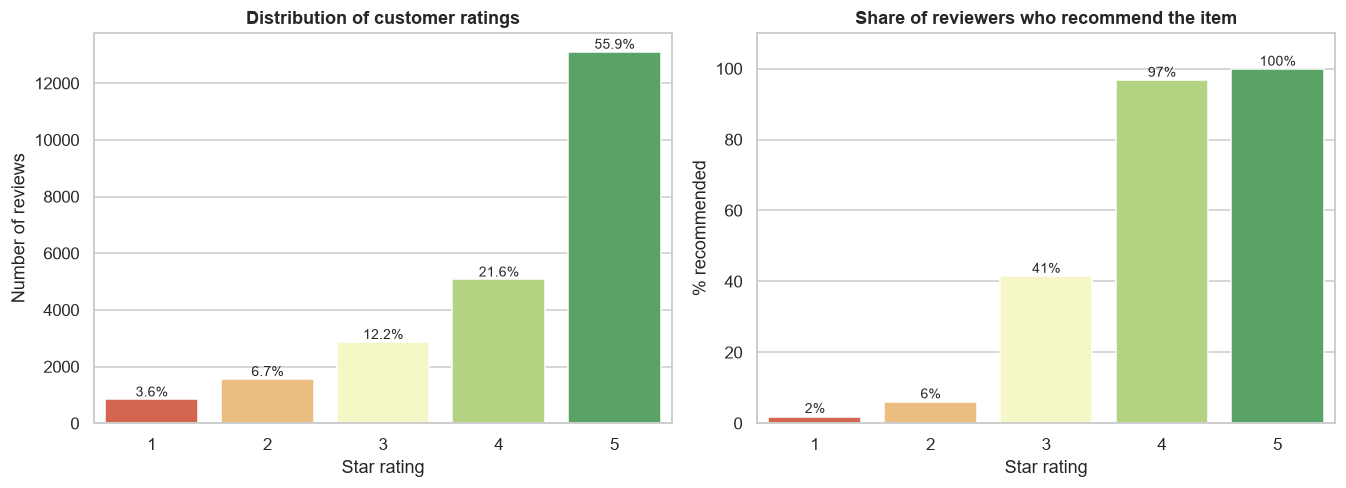

In [16]:
palette = sns.color_palette("RdYlGn", 5)   # one colour per star rating (1 to 5)
ncols = 2 if "recommended" in df.columns else 1
fig, axes = plt.subplots(1, ncols, figsize=(6.2 * ncols, 4.6))
axes = np.atleast_1d(axes)

sns.countplot(data=df, x="rating", order=[1, 2, 3, 4, 5], palette=palette, ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height() / len(df):.1%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)
axes[0].set_title("Distribution of customer ratings")
axes[0].set_xlabel("Star rating"); axes[0].set_ylabel("Number of reviews")

if "recommended" in df.columns:
    rec = df.groupby("rating")["recommended"].mean().mul(100)
    sns.barplot(x=rec.index, y=rec.values, palette=palette, ax=axes[1])
    for i, v in enumerate(rec.values):
        axes[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
    axes[1].set_ylim(0, 110)
    axes[1].set_title("Share of reviewers who recommend the item")
    axes[1].set_xlabel("Star rating"); axes[1].set_ylabel("% recommended")
savefig("fig01_rating_distribution")

### 4.3 Average rating by department and category
**What this does:** a helper function `summarize_by()` calculates, for any grouping column, the number of reviews, mean rating, share of low ratings and recommendation rate. We then plot the mean rating for each department and category as dots, with the overall average as a dashed line.
**Why:** categories with few reviews are noisy, so we only plot categories with at least 100 reviews and print the review count next to each dot.
**Note:** the x-axis here is zoomed in because the differences are small. Read the numbers, not just the distance between dots.

--- By department ---


,n_reviews,mean_rating,pct_low,pct_recommended
department,,,,
Unknown,14,5.00,0.00,100.00
Bottoms,3798,4.29,8.43,85.12
Intimate,1735,4.28,8.82,85.01
Jackets,1032,4.26,10.56,83.62
Tops,10455,4.17,10.66,81.49
Dresses,6311,4.15,10.90,80.81
Trend,119,3.82,18.49,73.95


--- By category ---


,n_reviews,mean_rating,pct_low,pct_recommended
category,,,,
Unknown,14,5.00,0.00,100.00
Casual bottoms,2,4.50,0.00,100.00
Layering,146,4.38,7.53,88.36
Jeans,1146,4.36,7.42,88.13
Lounge,691,4.30,6.95,85.96
Jackets,704,4.30,10.37,84.52
Sleep,228,4.29,10.96,85.53
Intimates,154,4.28,9.74,85.71
Legwear,165,4.28,9.70,86.06


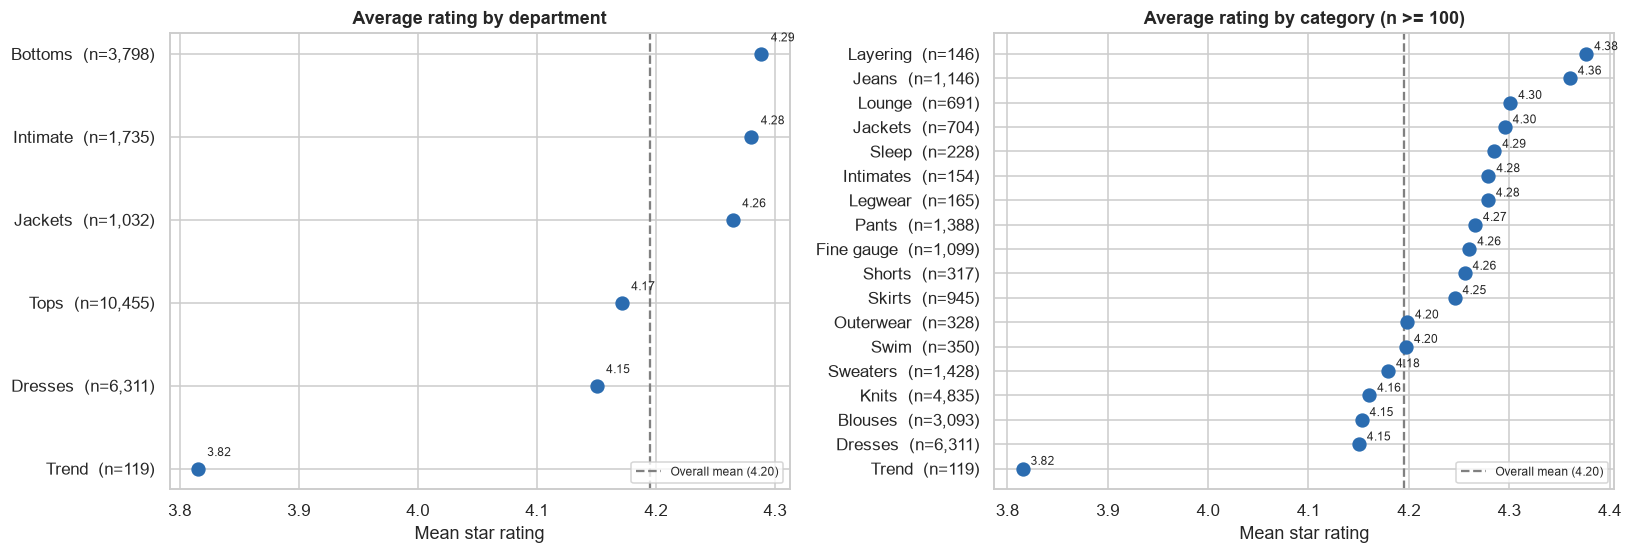

In [17]:
def summarize_by(frame, col):
    g = frame.groupby(col, observed=True)
    out = pd.DataFrame({
        "n_reviews":   g["rating"].size(),
        "mean_rating": g["rating"].mean(),
        "pct_low":     g["rating"].apply(lambda s: (s <= LOW_MAX).mean() * 100),
    })
    if "recommended" in frame.columns:
        out["pct_recommended"] = g["recommended"].mean() * 100
    return out.sort_values("mean_rating", ascending=False)

global_mean = df["rating"].mean()
dept = summarize_by(df, "department") if "department" in df.columns else None
cat  = summarize_by(df, "category")   if "category"   in df.columns else None

for name, tbl in [("department", dept), ("category", cat)]:
    if tbl is not None:
        print(f"--- By {name} ---")
        display(tbl.round(2))

def dot_plot(ax, tbl, title, min_n=100):
    t = tbl[tbl["n_reviews"] >= min_n].sort_values("mean_rating")
    ax.scatter(t["mean_rating"], range(len(t)), s=70, color="#2b6cb0", zorder=3)
    ax.axvline(global_mean, color="grey", ls="--", label=f"Overall mean ({global_mean:.2f})")
    ax.set_yticks(range(len(t))); ax.set_yticklabels([f"{i}  (n={int(n):,})" for i, n in zip(t.index, t["n_reviews"])])
    for y, v in enumerate(t["mean_rating"]):
        ax.text(v + 0.008, y + 0.15, f"{v:.2f}", fontsize=8)
    ax.set_title(title); ax.set_xlabel("Mean star rating"); ax.legend(loc="lower right", fontsize=8)

panels = [(t, n) for t, n in [(dept, "Average rating by department"), (cat, "Average rating by category (n >= 100)")] if t is not None]
fig, axes = plt.subplots(1, len(panels), figsize=(7.5 * len(panels), 5.2))
for ax, (t, n) in zip(np.atleast_1d(axes), panels):
    dot_plot(ax, t, n)
savefig("fig02_rating_by_department_category")

### 4.4 Review volume by department and category
**What this does:** shows how many reviews each department and category has.
**Why:** volume tells us where customers are most engaged and how much to trust each category's average.

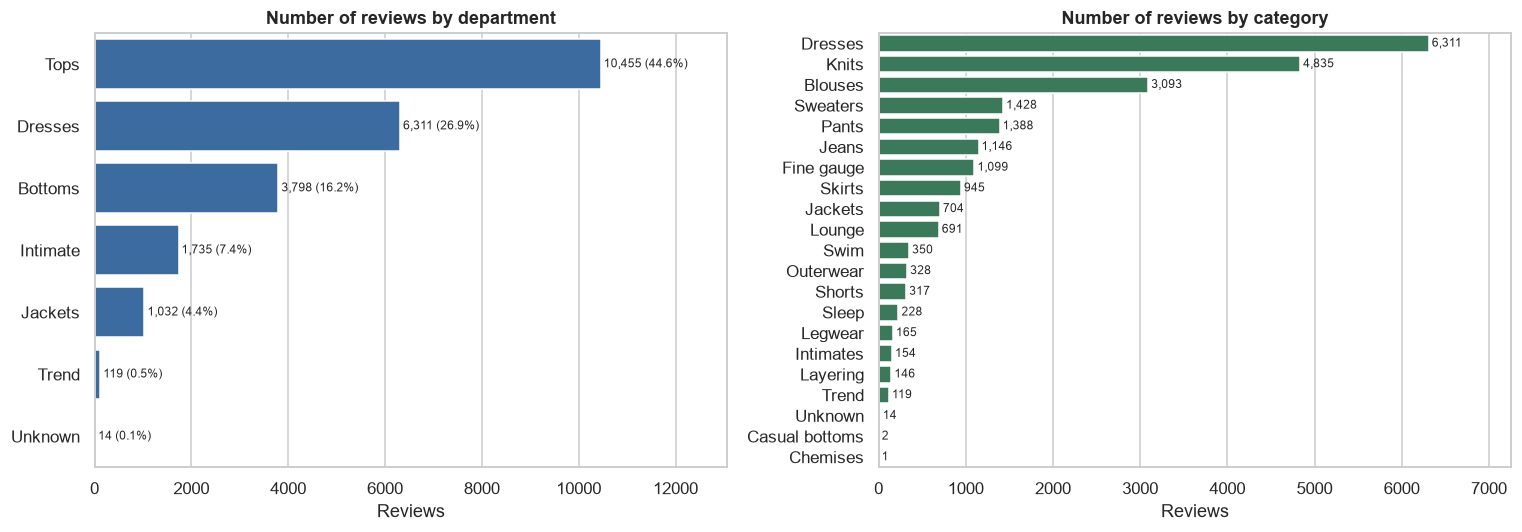

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if dept is not None:
    d = dept["n_reviews"].sort_values(ascending=False)
    sns.barplot(x=d.values, y=d.index, color="#2b6cb0", ax=axes[0])
    for i, v in enumerate(d.values):
        axes[0].text(v, i, f" {v:,} ({v / len(df):.1%})", va="center", fontsize=8)
    axes[0].set_title("Number of reviews by department"); axes[0].set_xlabel("Reviews"); axes[0].set_ylabel("")
    axes[0].set_xlim(0, d.max() * 1.25)
if cat is not None:
    c = cat["n_reviews"].sort_values(ascending=False)
    sns.barplot(x=c.values, y=c.index, color="#2f855a", ax=axes[1])
    for i, v in enumerate(c.values):
        axes[1].text(v, i, f" {v:,}", va="center", fontsize=8)
    axes[1].set_title("Number of reviews by category"); axes[1].set_xlabel("Reviews"); axes[1].set_ylabel("")
    axes[1].set_xlim(0, c.max() * 1.15)
savefig("fig03_review_volume")

### 4.5 Best and worst products (with a minimum-review rule)
**What this does:** builds a table with one row per product. A product with only one 5-star review has a "perfect" average but proves nothing, so we only rank products with at least `MIN_REVIEWS` reviews.
We also compute a **shrunk rating**: a product's average is pulled toward the overall average, more strongly when it has few reviews. This gives a fairer score for *all* products.
Formula: `(n x product_mean + k x overall_mean) / (n + k)`, with `k = PRIOR_WEIGHT`.

In [19]:
g = df.groupby("product_id")
prod = pd.DataFrame({
    "n_reviews":   g["rating"].size(),
    "mean_rating": g["rating"].mean(),
    "pct_low":     g["rating"].apply(lambda s: (s <= LOW_MAX).mean() * 100),
})
if "recommended" in df.columns:
    prod["pct_recommended"] = g["recommended"].mean() * 100
for col in ["department", "category"]:
    if col in df.columns:
        prod[col] = g[col].agg(lambda s: s.mode().iat[0])
prod["shrunk_rating"] = (prod["n_reviews"] * prod["mean_rating"] + PRIOR_WEIGHT * global_mean) / (prod["n_reviews"] + PRIOR_WEIGHT)

print(f"Products: {len(prod):,} | median reviews per product: {prod['n_reviews'].median():.0f} | "
      f"products with >= {MIN_REVIEWS} reviews: {(prod['n_reviews'] >= MIN_REVIEWS).sum()} "
      f"({(prod['n_reviews'] >= MIN_REVIEWS).mean():.1%}), covering "
      f"{prod.loc[prod['n_reviews'] >= MIN_REVIEWS, 'n_reviews'].sum() / len(df):.1%} of all reviews")

eligible = prod[prod["n_reviews"] >= MIN_REVIEWS]
top    = eligible.sort_values(["mean_rating", "n_reviews"], ascending=[False, False]).head(10)
bottom = eligible.sort_values(["mean_rating", "n_reviews"], ascending=[True,  False]).head(10)
print(f"\nTop 10 products (>= {MIN_REVIEWS} reviews):");    display(top.round(2))
print(f"Bottom 10 products (>= {MIN_REVIEWS} reviews):");   display(bottom.round(2))

Products: 1,206 | median reviews per product: 2 | products with >= 30 reviews: 139 (11.5%), covering 83.4% of all reviews

Top 10 products (>= 30 reviews):


,n_reviews,mean_rating,pct_low,pct_recommended,department,category,shrunk_rating
product_id,,,,,,,
906,37,4.73,0.00,94.59,Tops,Fine gauge,4.62
1123,30,4.70,0.00,100.00,Jackets,Outerwear,4.57
1024,35,4.66,2.86,97.14,Bottoms,Jeans,4.55
964,77,4.62,5.19,90.91,Jackets,Jackets,4.57
839,48,4.56,0.00,95.83,Tops,Blouses,4.50
834,149,4.54,4.70,93.29,Tops,Blouses,4.52
985,47,4.51,4.26,93.62,Jackets,Jackets,4.46
869,50,4.50,4.00,94.00,Tops,Knits,4.45
939,83,4.48,4.82,89.16,Tops,Sweaters,4.45


Bottom 10 products (>= 30 reviews):


,n_reviews,mean_rating,pct_low,pct_recommended,department,category,shrunk_rating
product_id,,,,,,,
1084,72,3.46,27.78,70.83,Dresses,Dresses,3.55
986,32,3.47,34.38,62.50,Jackets,Jackets,3.64
1088,30,3.57,23.33,63.33,Dresses,Dresses,3.72
838,37,3.59,29.73,64.86,Tops,Blouses,3.72
1079,63,3.62,17.46,65.08,Dresses,Dresses,3.70
844,50,3.66,22.00,62.00,Tops,Blouses,3.75
870,53,3.66,24.53,66.04,Tops,Knits,3.75
1076,46,3.67,28.26,69.57,Dresses,Dresses,3.77
1116,35,3.71,25.71,71.43,Jackets,Outerwear,3.82


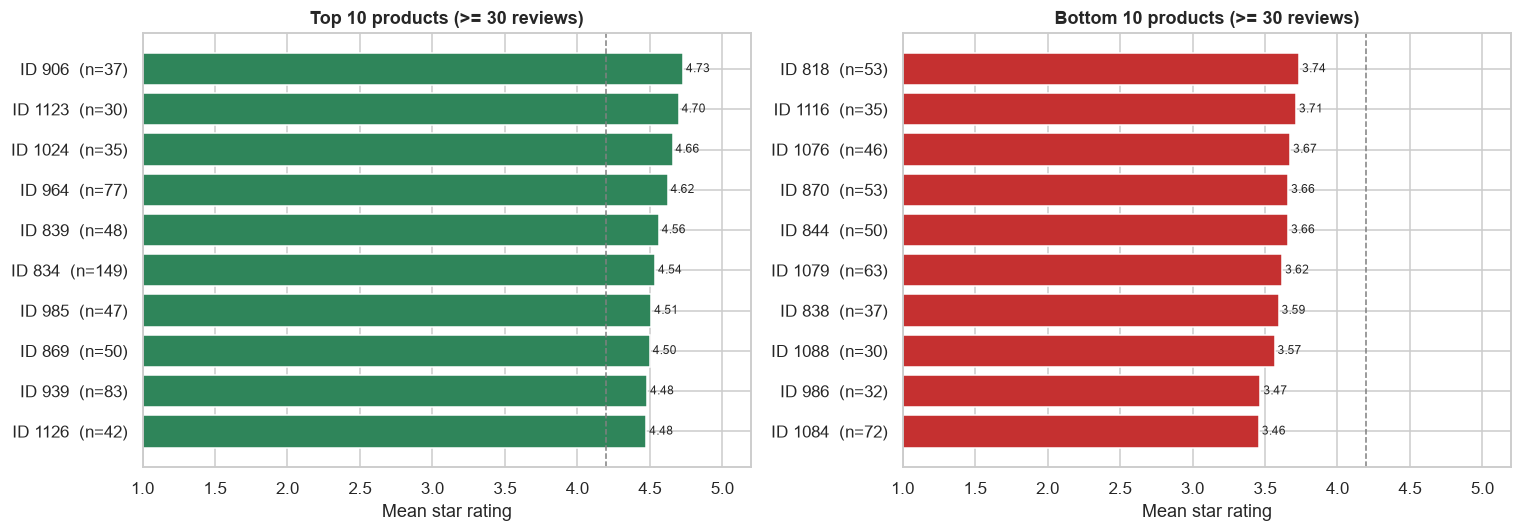

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, t, title, colr in [(axes[0], top.iloc[::-1], f"Top 10 products (>= {MIN_REVIEWS} reviews)", "#2f855a"),
                           (axes[1], bottom, f"Bottom 10 products (>= {MIN_REVIEWS} reviews)", "#c53030")]:
    labels = [f"ID {i}  (n={int(n)})" for i, n in zip(t.index, t["n_reviews"])]
    ax.barh(labels, t["mean_rating"], color=colr)
    for y, v in enumerate(t["mean_rating"]):
        ax.text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=8)
    ax.axvline(global_mean, color="grey", ls="--", lw=1)
    ax.set_xlim(1, 5.2); ax.set_title(title); ax.set_xlabel("Mean star rating")
savefig("fig04_top_bottom_products")

### 4.6 Relationship between review count and average rating
**What this does:** a scatter plot of each product's number of reviews (log scale) against its average rating, plus Spearman rank correlations.
**Why Spearman:** it measures whether the two rankings move together without assuming a straight-line relationship, and it is less affected by extreme values.
**Caution:** a correlation shows that two things move together. It does **not** show that one *causes* the other.
**Reading the shape:** products with few reviews scatter widely (small samples are noisy). The cloud narrows as reviews increase.

All products (n=1206):          rho = -0.186, p = 6.78e-11
Products with >= 5 reviews (n=373):  rho = +0.002, p = 0.964
Products with >= 30 reviews (n=139): rho = +0.130, p = 0.126


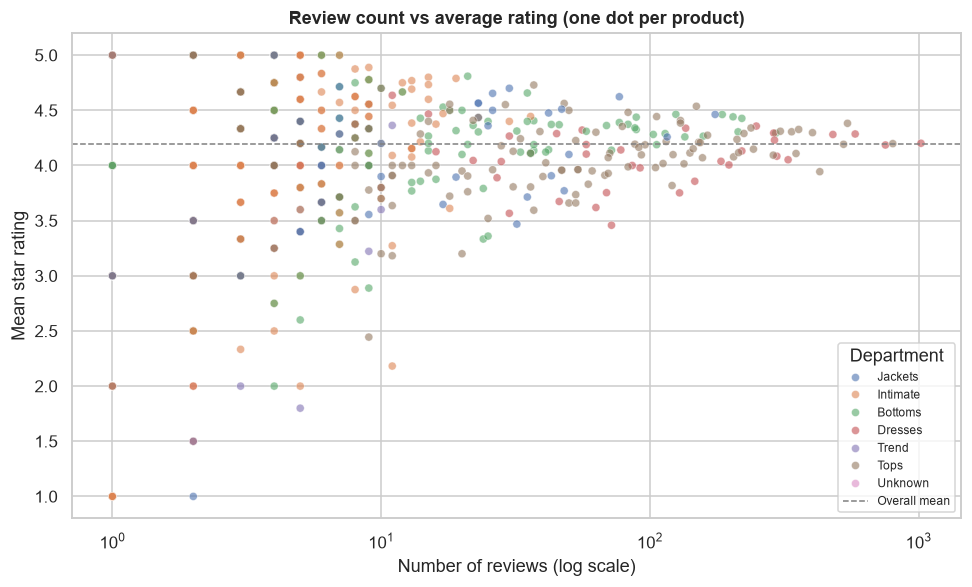

In [21]:
rho_all, p_all = spearmanr(prod["n_reviews"], prod["mean_rating"])
sub5 = prod[prod["n_reviews"] >= 5]
rho_5, p_5 = spearmanr(sub5["n_reviews"], sub5["mean_rating"])
rho_30, p_30 = spearmanr(eligible["n_reviews"], eligible["mean_rating"])
print(f"All products (n={len(prod)}):          rho = {rho_all:+.3f}, p = {p_all:.3g}")
print(f"Products with >= 5 reviews (n={len(sub5)}):  rho = {rho_5:+.3f}, p = {p_5:.3g}")
print(f"Products with >= {MIN_REVIEWS} reviews (n={len(eligible)}): rho = {rho_30:+.3f}, p = {p_30:.3g}")

fig, ax = plt.subplots(figsize=(9, 5.5))
hue = "department" if "department" in prod.columns else None
sns.scatterplot(data=prod, x="n_reviews", y="mean_rating", hue=hue, alpha=.6, s=28, ax=ax)
ax.set_xscale("log"); ax.axhline(global_mean, color="grey", ls="--", lw=1, label="Overall mean")
ax.set_title("Review count vs average rating (one dot per product)")
ax.set_xlabel("Number of reviews (log scale)"); ax.set_ylabel("Mean star rating")
ax.legend(title="Department", fontsize=8, loc="lower right")
savefig("fig05_reviews_vs_rating")

### 4.7 Time trends and verified purchases (only if the columns exist)
**What this does:** two helper functions that plot monthly rating trends and compare verified vs unverified reviews. They run automatically **only if** a date or verified column was detected.
**This dataset has neither**, so the cell prints a message and moves on. The functions are included so the same notebook works on other review datasets, such as Amazon. They were checked on a small test table but not on real data from this project.

In [22]:
def plot_rating_trend(frame):
    d = frame.copy()
    d["date"] = pd.to_datetime(d["date"], errors="coerce", unit="s" if pd.api.types.is_numeric_dtype(d["date"]) else None)
    d = d.dropna(subset=["date"])
    monthly = d.set_index("date")["rating"].resample("MS").agg(["mean", "size"])
    monthly = monthly[monthly["size"] >= 10]          # avoid noisy months
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(monthly.index, monthly["mean"], marker="o", ms=3)
    ax.set_title("Average rating per month (months with >= 10 reviews)")
    ax.set_xlabel("Month"); ax.set_ylabel("Mean star rating")
    savefig("fig_rating_trend")

def plot_verified(frame):
    v = frame.groupby("verified")["rating"].agg(["size", "mean"])
    print(v.round(2))
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.barplot(x=v.index.astype(str), y=v["mean"], ax=ax)
    ax.set_title("Mean rating: verified vs unverified"); ax.set_xlabel("Verified purchase"); ax.set_ylabel("Mean rating")
    savefig("fig_verified")

if "date" in df.columns:     plot_rating_trend(df)
else:                        print("No date column in this dataset -> rating-trend analysis skipped.")
if "verified" in df.columns: plot_verified(df)
else:                        print("No verified-purchase column in this dataset -> verified/unverified analysis skipped.")

No date column in this dataset -> rating-trend analysis skipped.
No verified-purchase column in this dataset -> verified/unverified analysis skipped.


### 4.8 Customer age, review length and helpful votes
**What this does:** looks at who the reviewers are and how engaged they are.
- Mean rating and recommendation rate by **age group** (left, with the number of reviews on each bar's label).
- **Review length by star rating** (middle): do unhappy customers write more?
- **Average helpful votes by star rating** (right).

**Reminder:** these are patterns in the data. They do not tell us *why* they occur.

,n,mean_rating,pct_low,pct_recommended
age_group,,,,
18-24,892,4.33,6.95,86.66
25-34,5172,4.14,11.02,80.01
35-44,7757,4.18,10.31,81.71
45-54,5108,4.17,10.71,82.07
55-64,3151,4.29,9.24,84.74
65+,1371,4.27,9.70,85.56


rating,1,2,3,4,5
median words,57.0,62.0,64.0,64.0,56.0


rating,1,2,3,4,5
mean,3.46,3.33,3.15,2.41,2.3
median,1.00,1.00,1.00,1.00,1.0


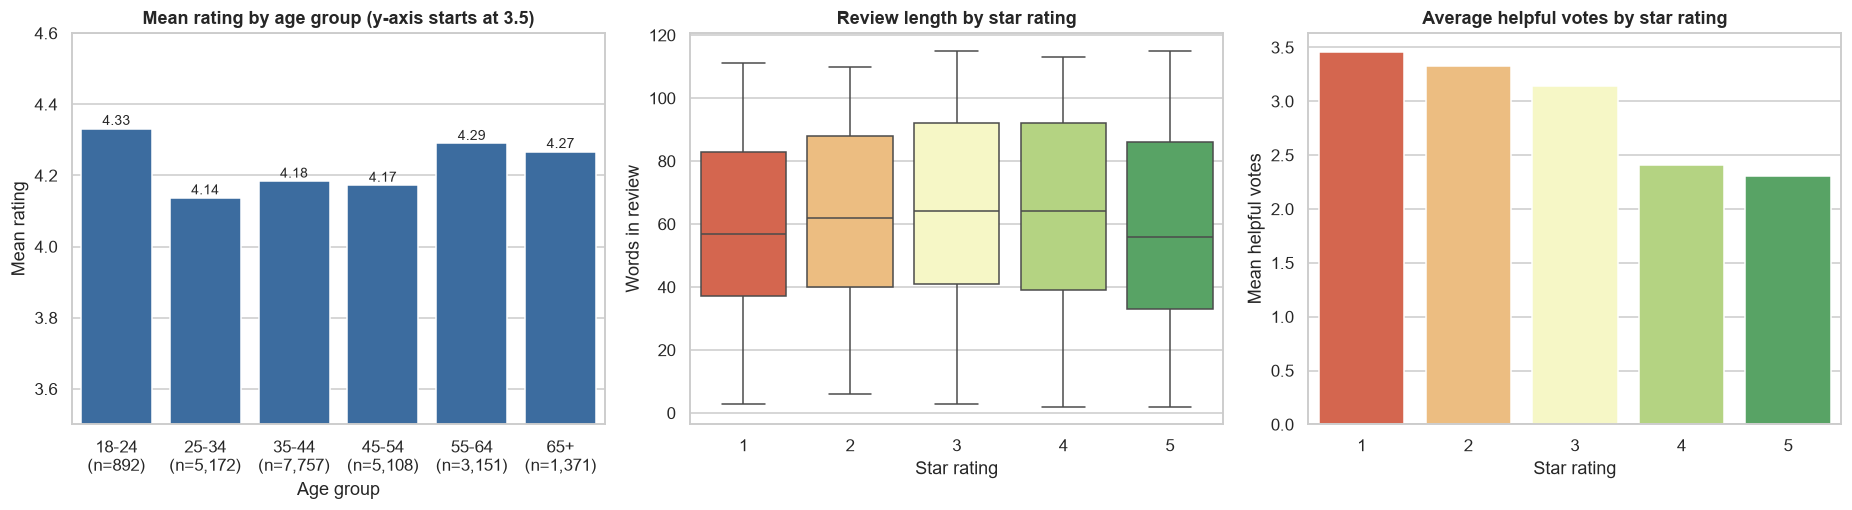

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

if "age_group" in df.columns:
    ag = df.groupby("age_group", observed=True).agg(n=("rating", "size"), mean_rating=("rating", "mean"),
                                                    pct_low=("rating", lambda s: (s <= LOW_MAX).mean() * 100))
    if "recommended" in df.columns:
        ag["pct_recommended"] = df.groupby("age_group", observed=True)["recommended"].mean() * 100
    display(ag.round(2))
    sns.barplot(x=[f"{i}\n(n={n:,})" for i, n in zip(ag.index, ag["n"])], y=ag["mean_rating"], color="#2b6cb0", ax=axes[0])
    axes[0].set_ylim(3.5, 4.6)
    for i, v in enumerate(ag["mean_rating"]):
        axes[0].text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
    axes[0].set_title("Mean rating by age group (y-axis starts at 3.5)"); axes[0].set_xlabel("Age group"); axes[0].set_ylabel("Mean rating")

if "word_count" in df.columns:
    sns.boxplot(data=df[df["has_text"]], x="rating", y="word_count", palette=palette, showfliers=False, ax=axes[1])
    axes[1].set_title("Review length by star rating"); axes[1].set_xlabel("Star rating"); axes[1].set_ylabel("Words in review")
    display(df[df["has_text"]].groupby("rating")["word_count"].median().to_frame("median words").T)

if "helpful_votes" in df.columns:
    hv = df.groupby("rating")["helpful_votes"].agg(["mean", "median"])
    display(hv.round(2).T)
    sns.barplot(x=hv.index, y=hv["mean"], palette=palette, ax=axes[2])
    axes[2].set_title("Average helpful votes by star rating"); axes[2].set_xlabel("Star rating"); axes[2].set_ylabel("Mean helpful votes")
savefig("fig06_age_length_votes")

## 5. Text analysis: what do customers talk about?

Only reviews that have text are used here (`has_text == True`). We compare **high-rated** reviews (4-5 stars) with **low-rated** reviews (1-2 stars).

### 5.1 Most common words and phrases
**What this does:** counts how many reviews contain each word (unigram) or two-word phrase (bigram), after removing very common "stop words" such as *the* and *and*. We keep negations (*not*, *no*, *never*) and *too*/*very* because phrases like "too small" and "not flattering" carry the meaning.
**Why share-of-reviews instead of raw counts:** there are many more high-rated than low-rated reviews, so raw counts would be unfair. We show the **percentage of reviews in each group** that contain the term.

Reviews with text: 22,639 | high-rated: 17,447 | low-rated: 2,369


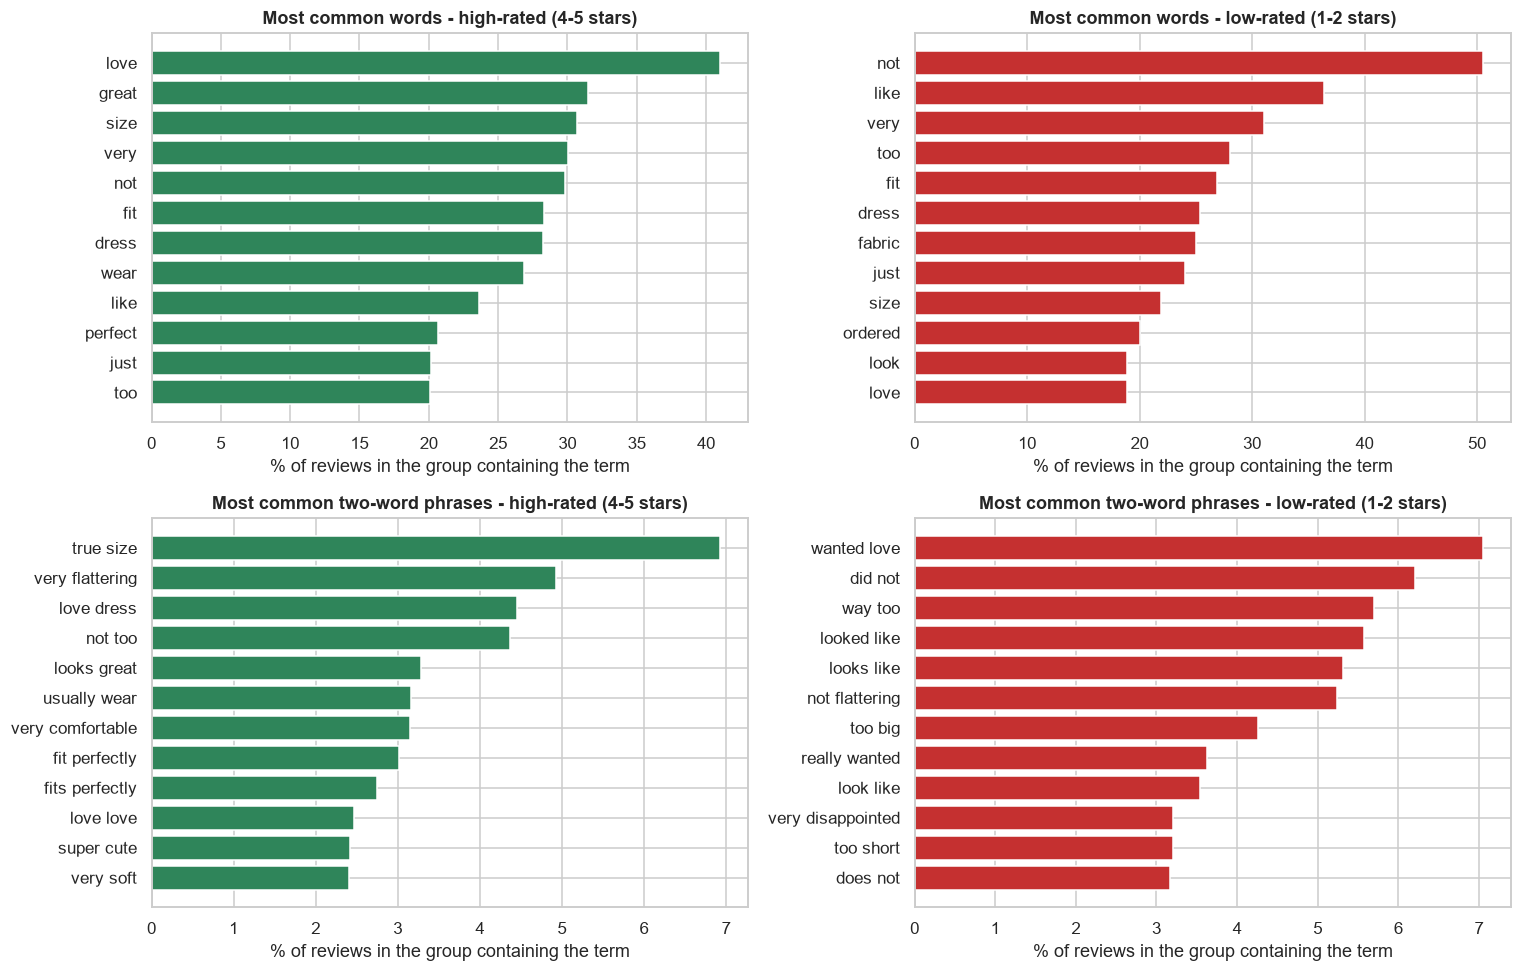

In [24]:
KEEP = {"not", "no", "never", "too", "very", "nor"}
EXTRA = {"dont", "didnt", "doesnt", "im", "ive", "isnt", "wasnt", "cant", "wont", "id", "ill", "thats",
         "youre", "theyre", "couldnt", "wouldnt", "shouldnt", "havent", "hasnt", "arent", "werent"}
STOP = sorted((set(ENGLISH_STOP_WORDS) - KEEP) | EXTRA)

txt = df[df["has_text"]].copy()
pos_txt = txt.loc[txt["rating"] >= HIGH_MIN, "clean_text"]
neg_txt = txt.loc[txt["rating"] <= LOW_MAX,  "clean_text"]
print(f"Reviews with text: {len(txt):,} | high-rated: {len(pos_txt):,} | low-rated: {len(neg_txt):,}")

def top_terms(texts, ngram_range=(1, 1), n=12):
    cv = CountVectorizer(stop_words=STOP, ngram_range=ngram_range, binary=True, min_df=2)
    X = cv.fit_transform(texts)
    share = np.asarray(X.sum(axis=0)).ravel() / X.shape[0] * 100
    return pd.Series(share, index=cv.get_feature_names_out()).sort_values(ascending=False).head(n)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for r, (ng, nm) in enumerate([((1, 1), "words"), ((2, 2), "two-word phrases")]):
    for c, (texts, nm2, colr) in enumerate([(pos_txt, "high-rated (4-5 stars)", "#2f855a"),
                                            (neg_txt, "low-rated (1-2 stars)", "#c53030")]):
        s = top_terms(texts, ng).iloc[::-1]
        axes[r, c].barh(s.index, s.values, color=colr)
        axes[r, c].set_title(f"Most common {nm} - {nm2}")
        axes[r, c].set_xlabel("% of reviews in the group containing the term")
savefig("fig07_top_words_phrases")

### 5.2 Which terms separate low-rated from high-rated reviews?
**What this does:** common words like "dress" appear in *every* group, so they do not explain dissatisfaction. Here we calculate a **log-odds ratio** that highlights terms much more typical of low-rated reviews (positive score) or of high-rated reviews (negative score). Only terms appearing in at least 30 reviews are considered, to avoid rare flukes.
**How to read:** a log-odds of 1 means the term is about 2.7x more likely (in proportion) in low-rated reviews; 2 means about 7.4x.

In [25]:
cv = CountVectorizer(stop_words=STOP, ngram_range=(1, 2), binary=True, min_df=30)
both = pd.concat([pos_txt, neg_txt])
X = cv.fit_transform(both)
is_pos = np.r_[np.ones(len(pos_txt)), np.zeros(len(neg_txt))].astype(bool)
pos_c = np.asarray(X[is_pos].sum(axis=0)).ravel()
neg_c = np.asarray(X[~is_pos].sum(axis=0)).ravel()
log_odds = np.log((neg_c + .5) / (len(neg_txt) + 1)) - np.log((pos_c + .5) / (len(pos_txt) + 1))

terms = pd.DataFrame({"term": cv.get_feature_names_out(),
                      "% of low-rated reviews": neg_c / len(neg_txt) * 100,
                      "% of high-rated reviews": pos_c / len(pos_txt) * 100,
                      "log_odds (low vs high)": log_odds})
print("Terms most typical of LOW-rated reviews:")
display(terms.sort_values("log_odds (low vs high)", ascending=False).head(15).round(2).reset_index(drop=True))
print("Terms most typical of HIGH-rated reviews:")
display(terms.sort_values("log_odds (low vs high)").head(15).round(2).reset_index(drop=True))

Terms most typical of LOW-rated reviews:


,term,% of low-rated reviews,% of high-rated reviews,log_odds (low vs high)
0,very disappointed,3.21,0.03,4.46
1,worst,1.18,0.02,4.09
2,poor quality,3.00,0.06,3.91
3,poorly,1.82,0.03,3.90
4,horrible,1.98,0.04,3.84
5,awful,2.66,0.06,3.71
6,poor,5.49,0.14,3.67
7,wanted like,2.11,0.05,3.67
8,high hopes,1.94,0.06,3.48
9,very unflattering,1.31,0.04,3.43


Terms most typical of HIGH-rated reviews:


,term,% of low-rated reviews,% of high-rated reviews,log_odds (low vs high)
0,fits great,0.00,1.37,-4.18
1,booties,0.00,1.35,-4.16
2,subtle,0.00,1.08,-3.94
3,super comfortable,0.00,1.03,-3.89
4,very versatile,0.00,0.87,-3.72
5,perfect fall,0.00,0.82,-3.66
6,great summer,0.00,0.82,-3.66
7,definitely recommend,0.00,0.79,-3.63
8,keeper,0.00,0.75,-3.58
9,cooler,0.00,0.72,-3.53


### 5.3 Complaint and praise themes
**What this does:** defines themes as lists of **specific phrases**, matched against the normalised review text. Complaint themes use problem phrases (for example *too small, runs large, cheap, see through, returned*); praise themes use positive phrases (for example *love, comfortable, flattering, true to size, compliments*). Each review is flagged if it contains at least one phrase of a theme.

**Why specific phrases instead of single words:** in an earlier draft of this analysis we used general keywords such as *fit*, *size* and *look*. They appeared just as often in happy reviews ("fits perfectly") as in unhappy ones, so they could not explain dissatisfaction. Phrases like *too small* point to an actual problem.

**Limits of this method:**
- It is keyword matching: it can miss complaints worded differently, and a phrase can occasionally appear in a positive review ("not too tight").
- The phrase lists were written by us after reading the common terms in 5.1 and 5.2. Another analyst might choose differently, so treat percentages as *indicative*.
- A theme being more common in low-rated reviews shows an **association**, not that it caused the low rating.

% of reviews in each rating group that mention each theme:


rating_group,Low (1-2),Neutral (3),High (4-5)
Runs small / too tight / too short,11.9,13.8,9.7
Runs large / too big / too long,14.3,19.2,12.5
Poor shape / unflattering cut,28.6,22.9,6.5
Fabric / quality problems,30.6,23.5,11.1
Differs from photo / expectation,24.2,19.3,16.4
Price / value complaint,5.4,4.7,1.9
Returned / disappointed,35.7,24.2,4.2
Love / looks great,40.1,48.5,68.6
Comfortable / soft,10.0,15.8,35.0
Flattering,10.6,12.2,18.0


Average rating with and without each theme (association only):


,mean rating when mentioned,mean rating when NOT mentioned,reviews mentioning,difference
Runs small / too tight / too short,4.00,4.20,2369,-0.20
Runs large / too big / too long,4.01,4.21,3066,-0.20
Poor shape / unflattering cut,3.37,4.28,2466,-0.92
Fabric / quality problems,3.62,4.28,3325,-0.65
Differs from photo / expectation,4.04,4.21,3977,-0.18
Price / value complaint,3.59,4.20,588,-0.61
Returned / disappointed,2.94,4.32,2256,-1.38
Love / looks great,4.40,3.81,14283,0.59
Comfortable / soft,4.55,4.03,6792,0.52
Flattering,4.43,4.14,3744,0.29


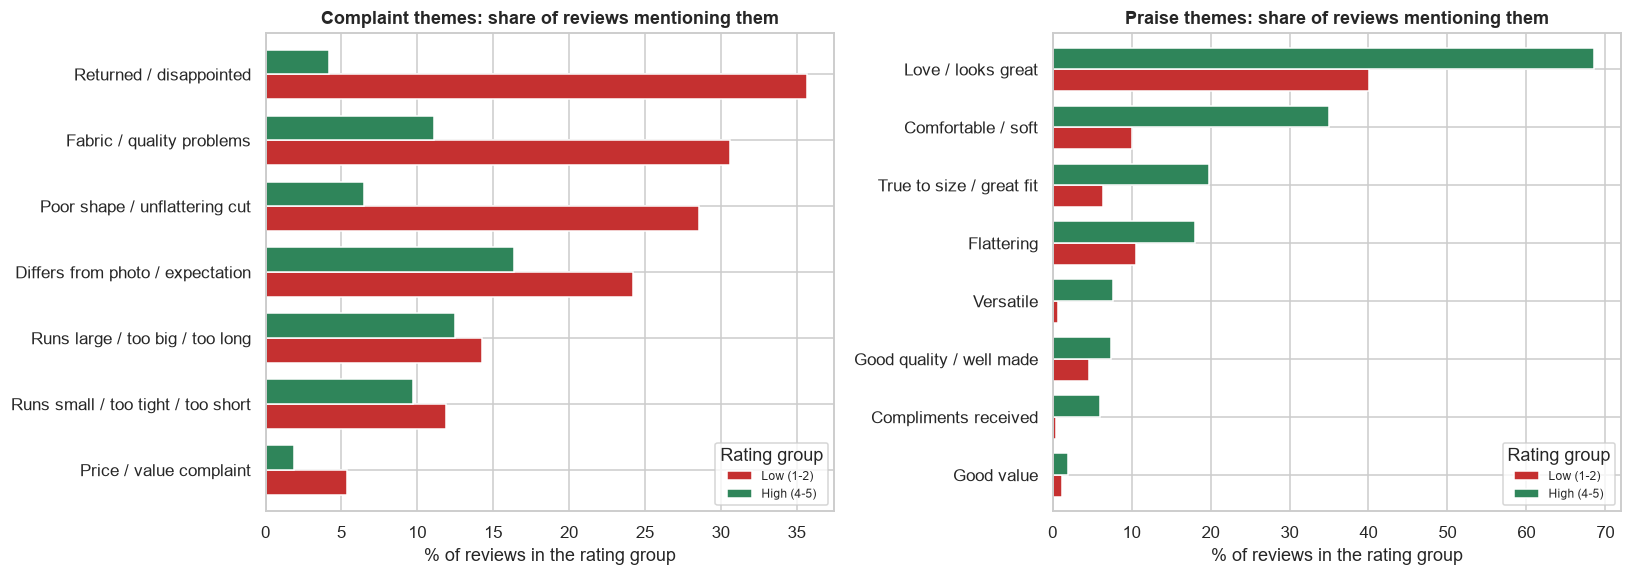

In [26]:
COMPLAINT_THEMES = {
    "Runs small / too tight / too short": r"\b(too small|runs small|run small|ran small|too tight|too snug|too short|too narrow|size up|sized up|sizing up|smaller than)\b",
    "Runs large / too big / too long":    r"\b(too big|too large|too loose|too long|too wide|runs large|runs big|run large|ran large|ran big|size down|sized down|sizing down|baggy|huge on)\b",
    "Poor shape / unflattering cut":      r"\b(unflattering|not flattering|boxy|frumpy|shapeless|tent|pregnant|maternity|sack|awkward|doesnt fit|didnt fit|does not fit|did not fit|not fit|poorly cut|bulky)\b",
    "Fabric / quality problems":          r"\b(cheap|cheaply|thin|flimsy|itchy|scratchy|see through|sheer|pilled|pilling|poor quality|poorly made|fell apart|ripped|shrunk|shrank|wrinkled|wrinkles|unraveled|frayed|stiff|faded|lint)\b",
    "Differs from photo / expectation":   r"\b(not as pictured|looks different|looked different|different than|different from|nothing like|not what i expected|didnt look like|does not look like|online|photo|picture|pictured|in person)\b",
    "Price / value complaint":            r"\b(overpriced|too expensive|expensive|pricey|not worth|waste of money|for the price)\b",
    "Returned / disappointed":            r"\b(returned|return it|returning it|sent back|send back|going back|going to return|had to return|have to return|disappointed|disappointing|disappointment|refund)\b",
}
PRAISE_THEMES = {
    "Love / looks great":         r"\b(love|loved|loves|perfect|gorgeous|beautiful|stunning|adorable|favorite|favourite|obsessed)\b",
    "Comfortable / soft":         r"\b(comfortable|comfy|comfort|soft|softness|cozy)\b",
    "Flattering":                 r"\b(flattering|flatters|slimming)\b",
    "True to size / great fit":   r"\b(true to size|tts|fits perfectly|fit perfectly|fits great|fit great|fits well|fit well|perfect fit|fits like a glove|fits beautifully)\b",
    "Compliments received":       r"\b(compliment|compliments|complimented)\b",
    "Good quality / well made":   r"\b(well made|great quality|good quality|high quality|excellent quality|beautiful fabric|lovely fabric|great fabric|nice fabric)\b",
    "Versatile":                  r"\b(versatile|dress up|dress down|goes with|wear it with)\b",
    "Good value":                 r"\b(great price|good price|great deal|worth it|worth every|bargain|great value)\b",
}
complaint_cols, praise_cols = list(COMPLAINT_THEMES), list(PRAISE_THEMES)
theme_cols = complaint_cols + praise_cols
for name, rx in {**COMPLAINT_THEMES, **PRAISE_THEMES}.items():
    txt[name] = txt["clean_text"].str.contains(rx, regex=True, na=False)

low_label, neu_label, high_label = df["rating_group"].cat.categories
theme_share = txt.groupby("rating_group", observed=True)[theme_cols].mean().mul(100).round(1)
print("% of reviews in each rating group that mention each theme:")
display(theme_share.T)

mean_when = pd.DataFrame({
    "mean rating when mentioned":     [txt.loc[txt[t], "rating"].mean() for t in theme_cols],
    "mean rating when NOT mentioned": [txt.loc[~txt[t], "rating"].mean() for t in theme_cols],
    "reviews mentioning":             [int(txt[t].sum()) for t in theme_cols]}, index=theme_cols)
mean_when["difference"] = mean_when.iloc[:, 0] - mean_when.iloc[:, 1]
print("Average rating with and without each theme (association only):")
display(mean_when.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
for ax, cols, title in [(axes[0], complaint_cols, "Complaint themes: share of reviews mentioning them"),
                        (axes[1], praise_cols,    "Praise themes: share of reviews mentioning them")]:
    pdf = theme_share.loc[[low_label, high_label], cols].T.sort_values(low_label if cols is complaint_cols else high_label)
    pdf.plot.barh(ax=ax, color=["#c53030", "#2f855a"], width=.75)
    ax.set_title(title); ax.set_xlabel("% of reviews in the rating group"); ax.set_ylabel("")
    ax.legend(title="Rating group", fontsize=8)
savefig("fig08_complaint_praise_themes")

### 5.4 Which categories have which complaint themes?
**What this does:** for each category with at least 30 low-rated reviews that have text, shows the percentage of its **low-rated** reviews mentioning each complaint theme.
**Why:** a company can only act on a complaint if it knows *which product group* it belongs to. Percentages are based on small groups for some categories, so the `n` in each row label matters.

,Runs small / too tight / too short,Runs large / too big / too long,Poor shape / unflattering cut,Fabric / quality problems,Differs from photo / expectation,Price / value complaint,Returned / disappointed
Blouses (n=343),12.5,15.5,30.9,33.5,24.2,5.8,36.2
Dresses (n=680),11.9,15.1,32.6,27.4,25.7,5.6,38.4
Fine gauge (n=104),11.5,9.6,33.7,34.6,23.1,4.8,40.4
Jackets (n=72),15.3,13.9,23.6,36.1,29.2,13.9,33.3
Jeans (n=85),16.5,12.9,12.9,30.6,21.2,3.5,29.4
Knits (n=498),8.8,15.3,34.3,30.1,22.5,3.8,33.3
Lounge (n=46),8.7,13.0,19.6,50.0,21.7,10.9,34.8
Outerwear (n=36),8.3,19.4,27.8,30.6,36.1,0.0,41.7
Pants (n=122),18.0,12.3,12.3,31.1,16.4,5.7,30.3
Skirts (n=85),21.2,12.9,17.6,28.2,28.2,7.1,30.6


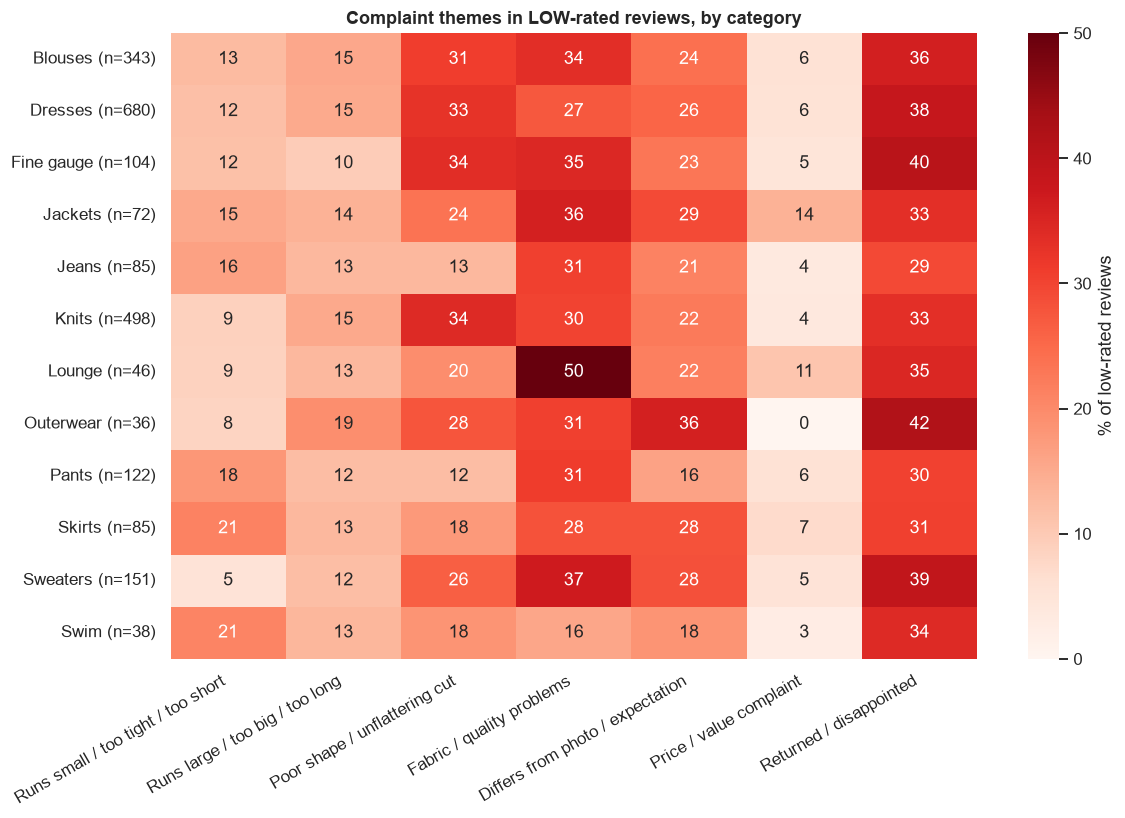

In [27]:
low_rev = txt[txt["rating"] <= LOW_MAX]
rows = {}
if "category" in low_rev.columns:
    for c, g in low_rev.groupby("category"):
        if len(g) >= 30:
            rows[f"{c} (n={len(g)})"] = g[complaint_cols].mean().mul(100)
class_low_themes = pd.DataFrame(rows).T
display(class_low_themes.round(1))

fig, ax = plt.subplots(figsize=(11, 0.45 * len(class_low_themes) + 2.2))
sns.heatmap(class_low_themes, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of low-rated reviews"}, ax=ax)
ax.set_title("Complaint themes in LOW-rated reviews, by category"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
savefig("fig09_category_complaint_heatmap")

## 6. Customer sentiment analysis

### 6.1 Method: VADER
**What it is:** VADER is a *lexicon and rule-based* sentiment tool (available through NLTK and as the `vaderSentiment` package). It has a dictionary of words with sentiment scores and rules for capitals, "!", negations ("not good") and intensifiers ("very good"). It returns a **compound score** from -1 (most negative) to +1 (most positive).
We use the standard cut-offs: compound >= 0.05 -> **Positive**, <= -0.05 -> **Negative**, otherwise **Neutral**.

**Why VADER:** it needs no training data, runs fast, is easy to explain in a viva, and is designed for informal text such as reviews.

**Limitations (be honest about these):**
1. It was not built for fashion reviews. Words such as "cheap" or "tight" depend on context, and it cannot understand sarcasm.
2. Mixed reviews ("beautiful dress but way too small") get an in-between score that hides the complaint.
3. A star rating and written sentiment can legitimately disagree, so **a mismatch is not automatically an error by either one.**
4. We have no human-labelled sentiment column, so we cannot calculate true accuracy directly. Sections 6.3 to 6.5 therefore use **proxy checks** and a **manual validation sample** you can label yourself.

In [28]:
sia = SentimentIntensityAnalyzer()
txt["compound"] = txt["full_text"].map(lambda t: sia.polarity_scores(t)["compound"])
txt["sentiment"] = np.select([txt["compound"] >= 0.05, txt["compound"] <= -0.05], ["Positive", "Negative"], default="Neutral")
txt["rating_label"] = np.select([txt["rating"] >= HIGH_MIN, txt["rating"] <= LOW_MAX], ["Positive", "Negative"], default="Neutral")

sent_counts = txt["sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"])
display(pd.DataFrame({"reviews": sent_counts, "%": (sent_counts / len(txt) * 100).round(1)}))
txt[["rating", "sentiment", "compound", "full_text"]].head(5)

,reviews,%
sentiment,,
Positive,21221,93.7
Neutral,184,0.8
Negative,1234,5.5


,rating,sentiment,compound,full_text
0,4,Positive,0.8932,Absolutely wonderful - silky and sexy and comf...
1,5,Positive,0.9729,Love this dress! it's sooo pretty. i happened ...
2,3,Positive,0.9208,Some major design flaws. I had such high hopes...
3,5,Positive,0.7182,"My favorite buy!. I love, love, love this jump..."
4,5,Positive,0.9436,Flattering shirt. This shirt is very flatterin...


### 6.2 Compare sentiment with star ratings
**What this does:** (left) for each star rating, the share of reviews VADER labelled positive, neutral or negative; (right) the distribution of compound scores per star rating.
**How to read:** if VADER and stars agree, the 5-star row should be mostly positive and the 1-star row mostly negative. The off-diagonal cells are the disagreements.

sentiment,Positive,Neutral,Negative
rating,,,
1,60.3,3.3,36.4
2,74.5,3.2,22.2
3,85.0,2.2,12.8
4,96.6,0.5,2.9
5,99.1,0.2,0.7


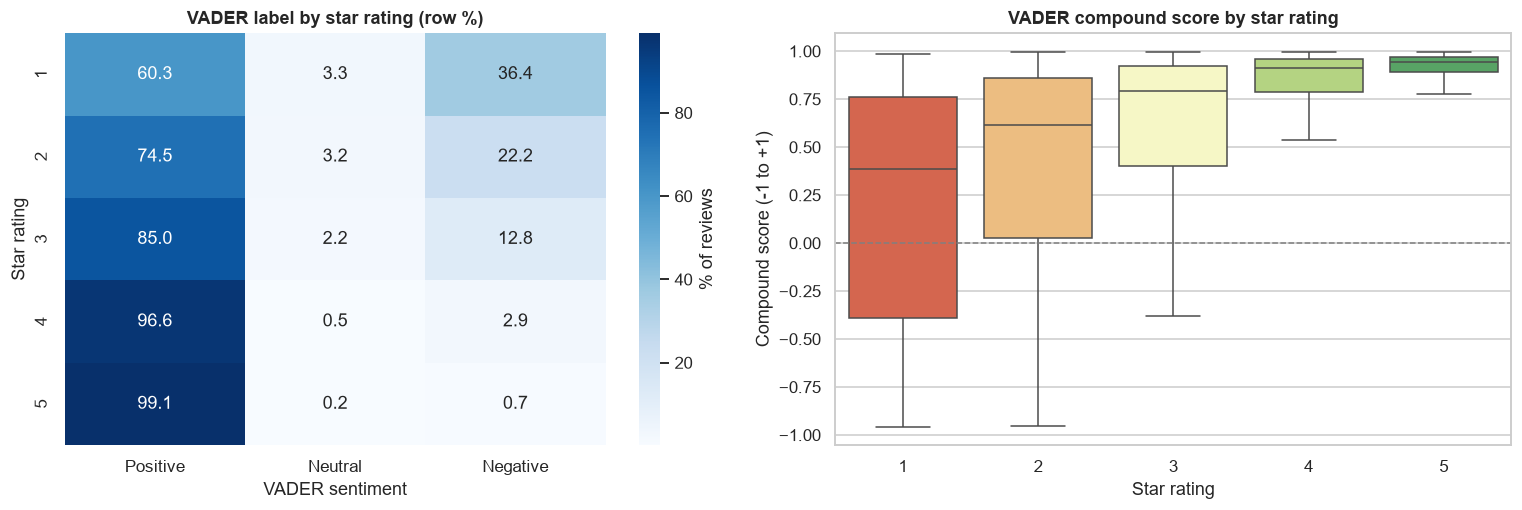

Spearman correlation between star rating and VADER compound score: rho = +0.452 (p = 0)


In [29]:
ct = pd.crosstab(txt["rating"], txt["sentiment"], normalize="index").mul(100)[["Positive", "Neutral", "Negative"]]
display(ct.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of reviews"}, ax=axes[0])
axes[0].set_title("VADER label by star rating (row %)"); axes[0].set_xlabel("VADER sentiment"); axes[0].set_ylabel("Star rating")
sns.boxplot(data=txt, x="rating", y="compound", palette=palette, showfliers=False, ax=axes[1])
axes[1].axhline(0, color="grey", ls="--", lw=1)
axes[1].set_title("VADER compound score by star rating"); axes[1].set_xlabel("Star rating"); axes[1].set_ylabel("Compound score (-1 to +1)")
savefig("fig10_sentiment_vs_rating")

rho_s, p_s = spearmanr(txt["rating"], txt["compound"])
print(f"Spearman correlation between star rating and VADER compound score: rho = {rho_s:+.3f} (p = {p_s:.3g})")

### 6.3 Evaluation check 1: agreement with a rating-based proxy
**What this does:** treats "4-5 stars = positive, 3 = neutral, 1-2 = negative" as a *rough reference* and measures agreement (accuracy, macro F1, per-class precision/recall).
**Not a true accuracy:** the brief warns that a star rating does not always equal the sentiment of the text. So this number measures **agreement with stars**, not correctness. We expect it to be imperfect, especially for the Neutral class (3 stars are mixed by nature).

In [30]:
labels = ["Negative", "Neutral", "Positive"]
agree = accuracy_score(txt["rating_label"], txt["sentiment"])
macro = f1_score(txt["rating_label"], txt["sentiment"], average="macro", labels=labels)
print(f"Agreement with rating-based proxy: accuracy = {agree:.3f}, macro F1 = {macro:.3f}\n")
always_pos = (txt["rating_label"] == "Positive").mean()
print(f"Baseline: labelling EVERY review 'Positive' would already agree with the proxy on {always_pos:.1%} of reviews.")
sub = txt[txt["rating"].isin([1, 2, 4, 5])]
auc_sep = roc_auc_score((sub["rating"] >= HIGH_MIN).astype(int), sub["compound"])
print(f"ROC-AUC of the compound score for separating 4-5 star from 1-2 star reviews: {auc_sep:.3f} (0.5 = no better than chance)\n")
print(classification_report(txt["rating_label"], txt["sentiment"], labels=labels, digits=3))
cm = pd.DataFrame(confusion_matrix(txt["rating_label"], txt["sentiment"], labels=labels),
                  index=[f"stars: {l}" for l in labels], columns=[f"VADER: {l}" for l in labels])
display(cm)

Agreement with rating-based proxy: accuracy = 0.790, macro F1 = 0.429

Baseline: labelling EVERY review 'Positive' would already agree with the proxy on 77.1% of reviews.
ROC-AUC of the compound score for separating 4-5 star from 1-2 star reviews: 0.852 (0.5 = no better than chance)

              precision    recall  f1-score   support

    Negative      0.521     0.271     0.357      2369
     Neutral      0.342     0.022     0.042      2823
    Positive      0.809     0.984     0.888     17447

    accuracy                          0.790     22639
   macro avg      0.558     0.426     0.429     22639
weighted avg      0.721     0.790     0.727     22639



,VADER: Negative,VADER: Neutral,VADER: Positive
stars: Negative,643,77,1649
stars: Neutral,361,63,2399
stars: Positive,230,44,17173


### 6.4 Where do sentiment and stars disagree?
**What this does:** counts and shows a **random** sample (not hand-picked) of (a) high-star reviews with negative text and (b) low-star reviews with positive text.
**Why:** reading real disagreements shows *why* the tool or the star rating can mislead (for example: praise for the fabric but a complaint about size).

In [31]:
hi_neg = txt[(txt["rating"] >= HIGH_MIN) & (txt["sentiment"] == "Negative")]
lo_pos = txt[(txt["rating"] <= LOW_MAX)  & (txt["sentiment"] == "Positive")]
print(f"4-5 star reviews labelled Negative by VADER: {len(hi_neg):,} ({len(hi_neg) / (txt['rating'] >= HIGH_MIN).sum():.1%} of 4-5 star reviews)")
print(f"1-2 star reviews labelled Positive by VADER: {len(lo_pos):,} ({len(lo_pos) / (txt['rating'] <= LOW_MAX).sum():.1%} of 1-2 star reviews)\n")

def show(sample, title):
    print(f"=== {title} (random sample, seed={RANDOM_STATE}) ===")
    for _, r in sample.iterrows():
        print(f"[{r['rating']} stars | compound {r['compound']:+.2f}] {r['full_text'][:260]}\n")

show(hi_neg.sample(4, random_state=RANDOM_STATE), "High stars, negative text")
show(lo_pos.sample(4, random_state=RANDOM_STATE), "Low stars, positive text")

4-5 star reviews labelled Negative by VADER: 230 (1.3% of 4-5 star reviews)
1-2 star reviews labelled Positive by VADER: 1,649 (69.6% of 1-2 star reviews)

=== High stars, negative text (random sample, seed=42) ===
[4 stars | compound -0.62] Bulky. This was a splurge piece for my fall wardrobe. however, i will be returning it. it's extremely heavy and bulky. the collar doesn't lay right--it's tall so it wants to flop over but it's too bulky to fold and stay down. i went a size down and the sleeves

[4 stars | compound -0.56] Adorable and unique. A scandalous mini skirt that isn't a skirt! beautiful pattern. does run a little big.

[4 stars | compound -0.45] Nothing special. I ordered the grey/yellow "here comes the sun" shirt. it's cute, but it runs quite large and isn't special enough for the price. meh.

[5 stars | compound -0.77] This dress make me laugh. I always chuckle when i see this dress because it looks so busy and so crazy with all the mixed prints, i think it's a lot of fun

### 6.5 Evaluation check 2: manual validation sample (do this yourself)
**What this does:** saves a CSV of up to 99 random reviews, balanced across VADER's three labels. You read each review and type `Positive`, `Neutral` or `Negative` in the `human_label` column. The evaluation cell below then calculates VADER's accuracy against **your** labels.
**Why:** this is the only way to honestly say how accurate VADER is on this data. **Until you label the file, the cell below will print a reminder and no accuracy figure should be quoted.**

In [32]:
VALIDATION_FILE = "results/manual_validation_sample.csv"
if not os.path.exists(VALIDATION_FILE):
    per = 33
    parts = [txt[txt["sentiment"] == lab].sample(min(per, (txt["sentiment"] == lab).sum()), random_state=RANDOM_STATE)
             for lab in ["Positive", "Neutral", "Negative"]]
    sample = (pd.concat(parts)[["rating", "sentiment", "compound", "full_text"]]
                .rename(columns={"sentiment": "vader_label"}))
    sample["human_label"] = ""
    sample.sample(frac=1, random_state=RANDOM_STATE).to_csv(VALIDATION_FILE, index_label="row_id")
    print(f"Created {VALIDATION_FILE} - open it, fill the 'human_label' column, save, and re-run this cell.")

val = pd.read_csv(VALIDATION_FILE)
val["human_label"] = val["human_label"].astype(str).str.strip().str.capitalize()
done = val[val["human_label"].isin(["Positive", "Neutral", "Negative"])]
if len(done) < 30:
    print(f"Only {len(done)} reviews labelled so far (need at least 30). Manual validation NOT yet done, so no true accuracy is reported.")
    manual_accuracy = None
else:
    manual_accuracy = accuracy_score(done["human_label"], done["vader_label"])
    print(f"Labelled reviews: {len(done)} | VADER accuracy vs human labels: {manual_accuracy:.3f}")
    print(classification_report(done["human_label"], done["vader_label"], digits=3, zero_division=0))

Only 0 reviews labelled so far (need at least 30). Manual validation NOT yet done, so no true accuracy is reported.


## 7. Optional extension: can review text predict "would recommend"?

**Why this extension is justified:** the dataset contains a *real, customer-given label*, `Recommended IND` (1 = would recommend). Unlike star-derived proxies, this label was given by the reviewer, so we can use it to test whether the text carries real signal, and to compare a trained model with VADER on the same unseen reviews.

**Method:** TF-IDF turns each review into numbers (giving weight to distinctive words and two-word phrases), and logistic regression predicts recommend / not recommend. We split the data into **80% training and 20% testing** so the model is judged on reviews it has never seen. Star rating is **not** used as a feature.

**Metrics:** because only a minority of reviewers do not recommend, accuracy alone is misleading (always guessing "recommend" already scores high). So we also report precision, recall, F1 and ROC-AUC, and a majority-class baseline.

Test reviews: 4,528 | share recommending: 81.9%
Majority-class baseline accuracy: 0.819
Logistic regression accuracy:     0.890
ROC-AUC  logistic regression: 0.946 | VADER compound score alone: 0.787

                 precision    recall  f1-score   support

Not recommended      0.649     0.860     0.740       820
    Recommended      0.967     0.897     0.931      3708

       accuracy                          0.890      4528
      macro avg      0.808     0.879     0.835      4528
   weighted avg      0.909     0.890     0.896      4528



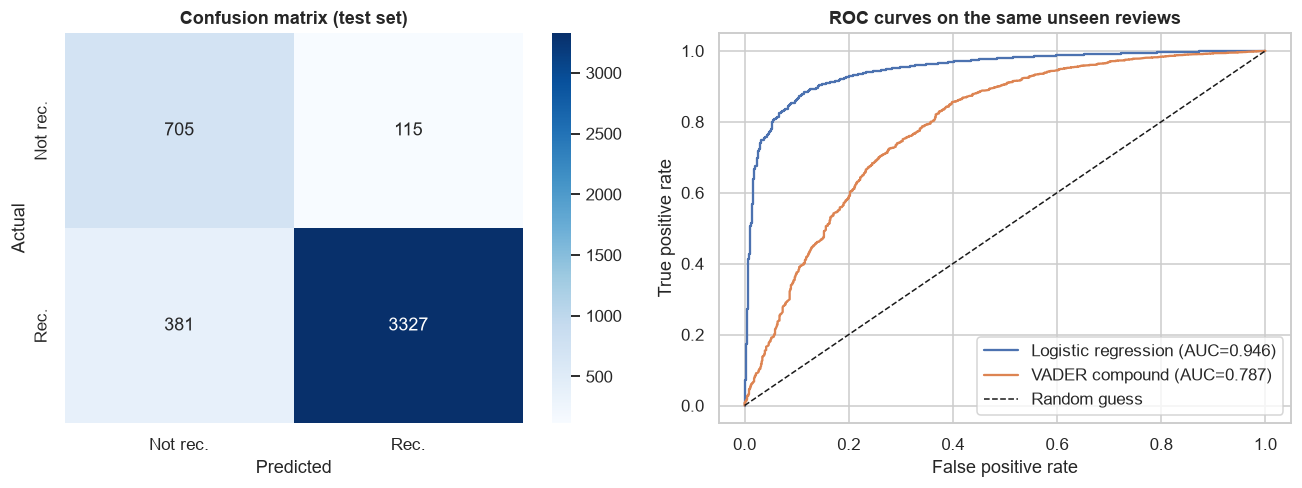

Phrases most associated with NOT recommending:
disappointed, wanted love, not, not flattering, unflattering, returning, huge, returned, return, poor, cheap, unfortunately, wanted, disappointing, looked

Phrases most associated with recommending:
love, perfect, great, comfortable, not too, unique, soft, little, fits, compliments, comfy, nice, beautiful, fun, easy


In [33]:
ml = txt.dropna(subset=["recommended"]).copy()
y = ml["recommended"].astype(int)
X_tr, X_te, y_tr, y_te, c_tr, c_te = train_test_split(ml["clean_text"], y, ml["compound"], test_size=0.2,
                                                       stratify=y, random_state=RANDOM_STATE)
vec = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=5, max_features=30000, sublinear_tf=True)
Xtr, Xte = vec.fit_transform(X_tr), vec.transform(X_te)       # fit on training data only (no leakage)
clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE).fit(Xtr, y_tr)
proba = clf.predict_proba(Xte)[:, 1]; pred = clf.predict(Xte)

baseline = max(y_te.mean(), 1 - y_te.mean())
auc_lr, auc_vader = roc_auc_score(y_te, proba), roc_auc_score(y_te, c_te)
print(f"Test reviews: {len(y_te):,} | share recommending: {y_te.mean():.1%}")
print(f"Majority-class baseline accuracy: {baseline:.3f}")
print(f"Logistic regression accuracy:     {accuracy_score(y_te, pred):.3f}")
print(f"ROC-AUC  logistic regression: {auc_lr:.3f} | VADER compound score alone: {auc_vader:.3f}\n")
print(classification_report(y_te, pred, target_names=["Not recommended", "Recommended"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cmx = confusion_matrix(y_te, pred)
sns.heatmap(cmx, annot=True, fmt="d", cmap="Blues", xticklabels=["Not rec.", "Rec."], yticklabels=["Not rec.", "Rec."], ax=axes[0])
axes[0].set_title("Confusion matrix (test set)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
for sc, nm in [(proba, f"Logistic regression (AUC={auc_lr:.3f})"), (c_te, f"VADER compound (AUC={auc_vader:.3f})")]:
    fpr, tpr, _ = roc_curve(y_te, sc); axes[1].plot(fpr, tpr, label=nm)
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[1].set_title("ROC curves on the same unseen reviews"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right")
savefig("fig11_model_results")

coef = pd.Series(clf.coef_[0], index=vec.get_feature_names_out()).sort_values()
print("Phrases most associated with NOT recommending:"); print(", ".join(coef.head(15).index))
print("\nPhrases most associated with recommending:");     print(", ".join(coef.tail(15).index[::-1]))

**How to read this:** if the model's AUC is clearly above 0.5, the review text really does contain information about whether customers recommend the product. If it beats VADER's AUC, a model trained on this retailer's own reviews captures their vocabulary better than a general-purpose dictionary. The top phrases are *associations*, not proof that a phrase causes dissatisfaction.

## 8. Key insights (generated from the calculated results)

**What this does:** pulls the numbers computed above into plain-language statements, so every figure quoted in the report traces back to a cell in this notebook. It also saves the key results to `results/summary.json` and the cleaned data to `data/cleaned_reviews.csv`.

In [34]:
D100 = dept[dept["n_reviews"] >= 100] if dept is not None else None
C100 = cat[cat["n_reviews"] >= 100]   if cat  is not None else None
top_n_low   = theme_share.loc[low_label].sort_values(ascending=False)
top_n_high  = theme_share.loc[high_label].sort_values(ascending=False)
lift = (theme_share.loc[low_label] / theme_share.loc[high_label]).sort_values(ascending=False)

print("OVERALL SATISFACTION")
print(f"  - {overall['reviews']:,} reviews of {overall['products']:,} products; mean rating {overall['mean_rating']:.2f}/5 (median {overall['median_rating']:.0f}).")
print(f"  - {overall['pct_high']:.1f}% of reviews are 4-5 stars; {overall['pct_low']:.1f}% are 1-2 stars.")
if "pct_recommended" in overall: print(f"  - {overall['pct_recommended']:.1f}% of reviewers say they would recommend the item.")

print("\nDEPARTMENTS / CATEGORIES (>= 100 reviews)")
if D100 is not None:
    print(f"  - Highest-rated department: {D100.index[0]} ({D100['mean_rating'].iloc[0]:.2f}); lowest: {D100.index[-1]} ({D100['mean_rating'].iloc[-1]:.2f}).")
if C100 is not None:
    print(f"  - Highest-rated category: {C100.index[0]} ({C100['mean_rating'].iloc[0]:.2f}); lowest: {C100.index[-1]} ({C100['mean_rating'].iloc[-1]:.2f}).")
    worst3 = C100.sort_values("pct_low", ascending=False).head(3)
    print("  - Categories with the highest share of 1-2 star reviews: " +
          "; ".join(f"{i} ({v:.1f}%)" for i, v in worst3["pct_low"].items()))
    spread = C100["mean_rating"].max() - C100["mean_rating"].min()
    print(f"  - Gap between best and worst category mean rating: {spread:.2f} stars.")

print("\nPRODUCTS (>= {} reviews)".format(MIN_REVIEWS))
print(f"  - Only {len(eligible)} of {len(prod):,} products reach the threshold, but they hold {eligible['n_reviews'].sum() / len(df):.1%} of reviews.")
print(f"  - Best: ID {top.index[0]} (mean {top['mean_rating'].iloc[0]:.2f}, n={int(top['n_reviews'].iloc[0])}). "
      f"Worst: ID {bottom.index[0]} (mean {bottom['mean_rating'].iloc[0]:.2f}, n={int(bottom['n_reviews'].iloc[0])}, "
      f"{bottom['pct_low'].iloc[0]:.0f}% low ratings).")
print(f"  - Review count vs mean rating (products with >= 5 reviews): Spearman rho = {rho_5:+.3f}. Correlation only, not causation.")

print("\nWHY CUSTOMERS ARE (UN)HAPPY (phrase-based themes, see limits in 5.3)")
c_low  = theme_share.loc[low_label, complaint_cols].sort_values(ascending=False)
c_lift = (theme_share.loc[low_label, complaint_cols] / theme_share.loc[high_label, complaint_cols].replace(0, np.nan)).sort_values(ascending=False)
p_high = theme_share.loc[high_label, praise_cols].sort_values(ascending=False)
print("  - Complaint themes most often found in LOW-rated reviews: " + "; ".join(f"{i} ({v:.0f}%)" for i, v in c_low.head(3).items()))
print("  - Complaint themes most over-represented in low- vs high-rated reviews: " + "; ".join(f"{i} ({v:.1f}x)" for i, v in c_lift.head(3).items()))
print("  - Praise themes most often found in HIGH-rated reviews: " + "; ".join(f"{i} ({v:.0f}%)" for i, v in p_high.head(3).items()))
if len(class_low_themes):
    top_theme_by_class = class_low_themes.idxmax(axis=1)
    print("  - Most common complaint theme in low-rated reviews, by category: " + "; ".join(f"{i.split(' (')[0]}: {t}" for i, t in top_theme_by_class.items()))

print("\nSENTIMENT vs STARS")
print(f"  - VADER agrees with the star-based proxy on {agree:.1%} of reviews (macro F1 {macro:.2f}); labelling everything Positive would give {always_pos:.1%}. This is agreement, not validated accuracy.")
print(f"  - VADER compound score separates 4-5 star from 1-2 star reviews with ROC-AUC {auc_sep:.3f}.")
print(f"  - {len(hi_neg) / (txt['rating'] >= HIGH_MIN).sum():.1%} of 4-5 star reviews read as negative to VADER; {len(lo_pos) / (txt['rating'] <= LOW_MAX).sum():.1%} of 1-2 star reviews read as positive.")
print(f"  - Star rating vs compound score: Spearman rho = {rho_s:+.3f}.")
print("  - Manual validation accuracy: " + (f"{manual_accuracy:.1%} on {len(done)} labelled reviews." if manual_accuracy is not None else "NOT YET DONE (label results/manual_validation_sample.csv)."))

print("\nPREDICTING 'RECOMMENDED' FROM TEXT")
print(f"  - Logistic regression AUC {auc_lr:.3f} vs VADER AUC {auc_vader:.3f}; baseline accuracy {baseline:.3f} vs model accuracy {accuracy_score(y_te, pred):.3f}.")

# ---- save outputs ----
summary = {
    "overall": {k: float(v) for k, v in overall.items()},
    "cleaning_log": cleaning_log,
    "rows_raw": int(len(raw)), "rows_clean": int(len(df)),
    "department_table": dept.round(3).reset_index().to_dict("records") if dept is not None else None,
    "category_table": cat.round(3).reset_index().to_dict("records") if cat is not None else None,
    "top_products": top.round(3).reset_index().to_dict("records"),
    "bottom_products": bottom.round(3).reset_index().to_dict("records"),
    "n_products": int(len(prod)), "n_products_eligible": int(len(eligible)),
    "median_reviews_per_product": float(prod["n_reviews"].median()),
    "spearman": {"all": float(rho_all), "ge5": float(rho_5), "ge_min": float(rho_30)},
    "theme_share": theme_share.to_dict("index"), "theme_mean_when": mean_when.round(3).to_dict("index"),
    "class_low_themes": class_low_themes.round(1).to_dict("index"),
    "sentiment_counts": sent_counts.to_dict(), "sentiment_vs_rating_pct": ct.round(1).to_dict("index"),
    "proxy_agreement": {"accuracy": float(agree), "macro_f1": float(macro), "always_positive_baseline": float(always_pos), "auc_low_vs_high": float(auc_sep)},
    "mismatch": {"high_star_negative": int(len(hi_neg)), "low_star_positive": int(len(lo_pos))},
    "rho_rating_compound": float(rho_s),
    "manual_validation_accuracy": None if manual_accuracy is None else float(manual_accuracy),
    "ml": {"baseline_acc": float(baseline), "lr_acc": float(accuracy_score(y_te, pred)),
           "lr_auc": float(auc_lr), "vader_auc": float(auc_vader), "lr_f1_macro": float(f1_score(y_te, pred, average="macro"))},
    "top_neg_phrases": list(coef.head(15).index), "top_pos_phrases": list(coef.tail(15).index[::-1]),
}
with open("results/summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
os.makedirs("data", exist_ok=True)
df.to_csv("data/cleaned_reviews.csv", index=False)
print("\nSaved results/summary.json and data/cleaned_reviews.csv")

OVERALL SATISFACTION
  - 23,464 reviews of 1,206 products; mean rating 4.20/5 (median 5).
  - 77.5% of reviews are 4-5 stars; 10.3% are 1-2 stars.
  - 82.2% of reviewers say they would recommend the item.

DEPARTMENTS / CATEGORIES (>= 100 reviews)
  - Highest-rated department: Bottoms (4.29); lowest: Trend (3.82).
  - Highest-rated category: Layering (4.38); lowest: Trend (3.82).
  - Categories with the highest share of 1-2 star reviews: Trend (18.5%); Blouses (11.3%); Outerwear (11.0%)
  - Gap between best and worst category mean rating: 0.56 stars.

PRODUCTS (>= 30 reviews)
  - Only 139 of 1,206 products reach the threshold, but they hold 83.4% of reviews.
  - Best: ID 906 (mean 4.73, n=37). Worst: ID 1084 (mean 3.46, n=72, 28% low ratings).
  - Review count vs mean rating (products with >= 5 reviews): Spearman rho = +0.002. Correlation only, not causation.

WHY CUSTOMERS ARE (UN)HAPPY (phrase-based themes, see limits in 5.3)
  - Complaint themes most often found in LOW-rated reviews

## 9. Business recommendations

> Each recommendation follows from a result in Section 8. They are **hypotheses worth acting on and testing**, not proven causes. Review text shows what customers *say*, not necessarily why they were unhappy.

**1. Build a watch-list from products that have enough evidence.**
Rank products with at least `MIN_REVIEWS` reviews by their share of low ratings and their "would recommend" rate (tables in 4.5). Send the worst performers for a quality, supplier and fit-specification check before changing anything else. Do not judge products with only a handful of reviews, because their averages are unreliable.

**2. Look first at the categories and departments with the lowest ratings and the highest share of 1-2 star reviews** (4.3 and Section 8). Use the category heatmap (5.4) to see *which* complaint dominates in each, so the fix matches the problem. Treat categories with small review counts cautiously.

**3. Improve fabric and construction quality, and describe materials honestly.**
Fabric and quality phrases (cheap, thin, see-through, itchy, pilling...) are far more common in low-rated reviews. Tighter quality control on those items, and clear product-page wording ("lightweight", "semi-sheer", "needs a slip"), should reduce disappointment.

**4. Improve fit information rather than only the garments.**
Poor shape / unflattering cut is strongly associated with low ratings, while plain "runs small / runs large" phrases appear in happy and unhappy reviews alike. That suggests customers tolerate sizing quirks when the item suits them, but are unhappy when the cut or silhouette is wrong. Useful steps: model photos across body types, measurements of the garment itself, and descriptions such as "boxy" or "fitted at the waist".

**5. Make photos and colours match reality.**
"Differs from photo / expectation" is more common in low-rated reviews. Show in-person or customer photos and check colour accuracy.

**6. Use "returned / disappointed" language as an early-warning signal.**
This theme shows the biggest gap between low- and high-rated reviews. Customer service can monitor it (weekly counts by product), contact affected customers, and feed the reasons back to merchandising.

**7. Triage reviews with a text model, with human checks.**
The optional model (Section 7) predicts "would recommend" from text far better than VADER does on unseen reviews. It could flag likely-unhappy customers for follow-up, but it must be monitored for errors on your own data before real use.

**8. Reuse what customers praise in marketing and product copy.**
Comfort, softness, compliments, versatility and true-to-size fit are the praise themes of high-rated reviews. Highlight them accurately on well-reviewed products.

**9. Do not rely on one signal.**
Star ratings, recommendation flags and text sentiment can disagree. Combine them, and always check sample reviews before drawing conclusions from sentiment scores alone.

## 10. Limitations

- **No dates or verified-purchase flags:** trend analysis and verified-vs-unverified comparisons were impossible with this file.
- **No product names:** products are identified only by `Clothing ID`, so we can say *which ID* performs well or badly, but not what the item is.
- **Most products have very few reviews:** product rankings are only reliable for products with at least `MIN_REVIEWS` reviews, so they cover only part of the catalogue.
- **Single retailer, self-selected reviewers:** people who write reviews are not a random sample of all customers, so results describe *reviewers*, not every buyer.
- **Keyword themes are approximate:** they detect mentions, not whether the mention is positive or negative.
- **VADER is a general-purpose tool:** it was not tuned for clothing reviews and cannot be called accurate without the manual validation in 6.5.
- **Association, not causation:** nothing here proves that a theme *causes* a low rating.
- **Anonymised and possibly pre-processed data:** the source dataset may already be a sample or filtered; we cannot verify this.

## 11. Conclusion and future scope

**Conclusion:** the notebook cleans the review data, measures customer satisfaction, identifies which categories and products need attention, summarises complaint and praise themes, and shows how text sentiment relates to star ratings. All numbers in Section 8 come from the executed code.

**Future scope:**
1. Label the validation sample (and more) to get a true accuracy for sentiment, and compare VADER with a fine-tuned transformer model.
2. Replace keyword themes with topic modelling (LDA or BERTopic) or aspect-based sentiment analysis, which scores sentiment *per topic* (fit, fabric, price...).
3. Re-run on a dataset with dates and verified purchases to study trends and review authenticity.
4. Join product names, prices and return rates to link feedback to business outcomes.
5. Build a dashboard (Streamlit or Power BI) so non-technical teams can explore the results.